# Predicting Student Dropout and Academic Success

**IT5022 Fundamentals of Machine Learning · Group Assignment (group of 2)**

| Member | Registration | Owns, as set out in the project plan |
|---|---|---|
| Kusal Dissanayake | MS26929064 | Random Forest and the decision trees behind it; PCA |
| Lahiru Sandeepa | MS26929378 | Logistic Regression; scaling; SMOTE, the threshold sweep and ROC/PR analysis; |



---

### Problem statement
Student dropout is costly for universities and students alike. Using information available at enrolment and after the
first two semesters, we predict whether a student will **Graduate**, remain **Enrolled**, or **Drop out** — a
**supervised, 3-class classification** problem that can power an early-warning / student-support system.

### Dataset
- **Name:** Predict Students' Dropout and Academic Success
- **Source:** UCI Machine Learning Repository, dataset **#697** — https://archive.ics.uci.edu/dataset/697 (DOI 10.24432/C5MC89)
- **Size:** 4,424 students · 36 features · target `{Dropout, Enrolled, Graduate}`
- **Features:** demographics (marital status, nationality, gender, age), socio-economic context (parents'
  qualifications/occupations, tuition fees up to date, scholarship holder, debtor), academic background (application
  mode, previous/admission grade) and **curricular-unit performance in semesters 1 & 2*

## 1. Imports

In [2]:
# Core libraries (same stack used across the IT5022 lab notebooks)
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_val_score, cross_validate)
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve,
                             precision_recall_curve, auc)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
print("Imports ready.")

Imports ready.


## 2. Data Loading

In [3]:
# Load UCI dataset #697 (primary: ucimlrepo package; fallback: local CSV saved by notebook 01)
def load_students():
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=697)
        X = ds.data.features.copy()
        y_raw = ds.data.targets.copy()
        df = pd.concat([X, y_raw], axis=1)
        print("Loaded from UCI repository (id=697).")
    except Exception as e:
        print("ucimlrepo unavailable, using local CSV:", e)
        df = pd.read_csv("data/students_dropout.csv")
    return df

df = load_students()
print("Shape:", df.shape)
df.head()

Loaded from UCI repository (id=697).
Shape: (4424, 37)


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


Shape: (4424, 37)
Total missing cells: 0 | Duplicate rows: 0


,Count,Percentage %
Target,,
Graduate,2209,49.9
Dropout,1421,32.1
Enrolled,794,17.9


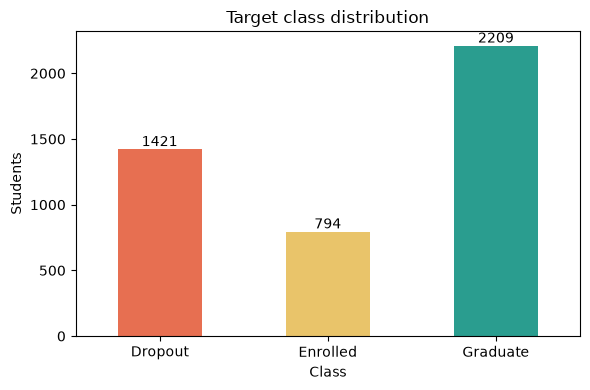

In [4]:
print("Shape:", df.shape)
print("Total missing cells:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
counts = df["Target"].value_counts()
display(pd.DataFrame({"Count": counts,
                      "Percentage %": df["Target"].value_counts(normalize=True).mul(100).round(1)}))
fig, ax = plt.subplots(figsize=(6,4))
counts.loc[["Dropout","Enrolled","Graduate"]].plot(kind="bar",
        color=["#e76f51","#e9c46a","#2a9d8f"], ax=ax)
ax.set_title("Target class distribution"); ax.set_xlabel("Class"); ax.set_ylabel("Students")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

### 2.1 Data audit


In [5]:
df.head()
df.info()

# summarise data type, missing counts/percentages and unique values for every column, and report exact duplicates.
summary = pd.DataFrame(index=df.columns)
summary.index.name = "Column"
summary["Data Type"] = df.dtypes.astype(str)
summary["Missing Count"] = df.isna().sum()
summary["Missing %"] = df.isna().mean().mul(100).round(2)
summary["Unique Values"] = df.nunique()
summary = summary.sort_values("Missing %", ascending=False)
display(summary)
print("Exact duplicate rows:", int(df.duplicated().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

,Data Type,Missing Count,Missing %,Unique Values
Column,,,,
Marital Status,int64,0,0.0,6
Application mode,int64,0,0.0,18
Application order,int64,0,0.0,8
Course,int64,0,0.0,17
Daytime/evening attendance,int64,0,0.0,2
Previous qualification,int64,0,0.0,17
Previous qualification (grade),float64,0,0.0,101
Nacionality,int64,0,0.0,21
Mother's qualification,int64,0,0.0,29


Exact duplicate rows: 0


## 3. Preprocessing & Feature Screening

The raw table becomes a matrix both models can use. Everything learned from data (encoder
levels, scaler means, PCA directions, screening scores) is learned from the training split
only and then applied unchanged to the test split, the rule Labs 04 and 05 set out.

### 3.1 Column names and column groups · *Lahiru, Kusal*

Two columns are renamed. The source misspells the nationality column as `Nacionality`, and
it codes `Gender` as 1 = male, 0 = female, so a column called `Gender` does not say which
value is 1; named `Male`, it reads correctly wherever it appears.

The 36 features then fall into three groups. Nine are national registry codes stored as
integers: `Course` 9254 is not "more" than `Course` 171, so these are categories with no
ordering. Eight are already 0/1 flags, and nineteen are genuine numbers or counts.

In [6]:
# fix the misspelt column and name the 0/1 gender flag after its value of 1
df = df.rename(columns={"Nacionality": "Nationality", "Gender": "Male"})

TARGET = "Target"
NOMINAL = ["Marital Status", "Application mode", "Course", "Previous qualification",
           "Nationality", "Mother's qualification", "Father's qualification",
           "Mother's occupation", "Father's occupation"]
BINARY = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
          "Tuition fees up to date", "Male", "Scholarship holder", "International"]
CONTINUOUS = (["Application order", "Previous qualification (grade)", "Admission grade",
               "Age at enrollment"]
              + [f"Curricular units {sem} sem ({kind})"
                 for sem in ("1st", "2nd")
                 for kind in ("credited", "enrolled", "evaluations", "approved", "grade",
                              "without evaluations")]
              + ["Unemployment rate", "Inflation rate", "GDP"])

# every feature belongs to exactly one group
assert len(NOMINAL + BINARY + CONTINUOUS) == 36
assert set(NOMINAL + BINARY + CONTINUOUS + [TARGET]) == set(df.columns)
print(f"nominal codes: {len(NOMINAL)} | binary flags: {len(BINARY)} | continuous: {len(CONTINUOUS)}")

df[NOMINAL].nunique().sort_values(ascending=False).rename("distinct codes").to_frame()

nominal codes: 9 | binary flags: 8 | continuous: 19


,distinct codes
Column,
Father's occupation,46
Father's qualification,34
Mother's occupation,32
Mother's qualification,29
Nationality,21
Application mode,18
Previous qualification,17
Course,17
Marital Status,6


### 3.2 Removing a redundant column · *Lahiru, Kusal*

`International` is not separate information: it is exactly "the nationality code is not 1
(Portuguese)". Keeping both adds a column and nothing else, so `International` is dropped.

In [7]:
is_foreign = (df["Nationality"] != 1).astype(int)
print("International == (Nationality != 1) for every row:", bool((df["International"] == is_foreign).all()))

df = df.drop(columns=["International"])
BINARY.remove("International")
print("features remaining:", df.shape[1] - 1)

International == (Nationality != 1) for every row: True
features remaining: 35


### 3.3 Four engineered features · *Lahiru, Kusal*

| feature | definition | why |
|---|---|---|
| `approval_rate_1st` | units approved ÷ units enrolled, 1st semester | 4 of 6 passed is not the same as 4 of 12 |
| `approval_rate_2nd` | the same for the 2nd semester | |
| `grade_trend` | 2nd semester grade − 1st semester grade | a falling and a recovering student can share an average |
| `total_approved` | units approved across both semesters | overall progress in one number |

Each is computed from a single row, so none can leak information between students, and they
are added before the split. A student enrolled in no units gets an approval rate of 0 rather
than a division by zero. These 180 students are kept: about 43% of them drop out, against
32% overall, though about as many graduate.

In [8]:
def approval_rate(approved, enrolled):
    # no units enrolled gives 0 instead of a division by zero
    return approved.div(enrolled.where(enrolled > 0)).fillna(0.0)

df["approval_rate_1st"] = approval_rate(df["Curricular units 1st sem (approved)"],
                                        df["Curricular units 1st sem (enrolled)"])
df["approval_rate_2nd"] = approval_rate(df["Curricular units 2nd sem (approved)"],
                                        df["Curricular units 2nd sem (enrolled)"])
df["grade_trend"] = df["Curricular units 2nd sem (grade)"] - df["Curricular units 1st sem (grade)"]
df["total_approved"] = (df["Curricular units 1st sem (approved)"]
                        + df["Curricular units 2nd sem (approved)"])

ENGINEERED = ["approval_rate_1st", "approval_rate_2nd", "grade_trend", "total_approved"]
CONTINUOUS_ALL = CONTINUOUS + ENGINEERED

print("students enrolled in no units, 1st semester:",
      int((df["Curricular units 1st sem (enrolled)"] == 0).sum()))
print("\nmean of each engineered feature by outcome:")
df.groupby(TARGET)[ENGINEERED].mean().round(3)

students enrolled in no units, 1st semester: 180

mean of each engineered feature by outcome:


Column,approval_rate_1st,approval_rate_2nd,grade_trend,total_approved
Target,,,,
Dropout,0.384,0.293,-1.357,4.492
Enrolled,0.688,0.649,-0.008,8.377
Graduate,0.903,0.900,0.054,12.409


### 3.4 Train/test split · *Lahiru, Kusal*

One split, made once and reused by both models: 80% for training and 20% held back for
testing, with `random_state=42` (Lab 03). For classification the split is stratified, so both
halves keep the original class proportions (Lab 05); this matters because `Enrolled` is only
17.9% of the data. The test set is not used again until section 6. Model selection uses
5-fold stratified cross-validation inside the training set.

In [9]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

assert len(X_train) == 3539 and len(X_test) == 885
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

pd.DataFrame({
    "train %": y_train.value_counts(normalize=True).mul(100).round(2),
    "test %": y_test.value_counts(normalize=True).mul(100).round(2),
})

Training samples: 3539
Testing samples : 885


,train %,test %
Target,,
Graduate,49.93,49.94
Dropout,32.13,32.09
Enrolled,17.94,17.97


### 3.5 Encoding the registry codes · *Lahiru, Kusal*

The nine registry-code columns are one-hot encoded. Keeping every level would create a column
for codes that only a handful of students have, which gives a model nothing to learn from.
`OneHotEncoder(min_frequency=0.01)` folds every level below 1% of the training rows into one
`infrequent` column per feature, and `handle_unknown="infrequent_if_exist"` sends a code never
seen in training into that same column instead of raising an error.

In [10]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist",
                        sparse_output=False)
encoder.fit(X_train[NOMINAL])

levels = pd.DataFrame({
    "levels": [len(c) for c in encoder.categories_],
    "folded into infrequent": [0 if f is None else len(f) for f in encoder.infrequent_categories_],
}, index=NOMINAL)
levels["columns after encoding"] = (levels["levels"] - levels["folded into infrequent"]
                                    + (levels["folded into infrequent"] > 0).astype(int))

print("columns from the nine nominal features:", len(encoder.get_feature_names_out()),
      "instead of", int(levels["levels"].sum()))
levels.sort_values("levels", ascending=False)

columns from the nine nominal features: 79 instead of 209


,levels,folded into infrequent,columns after encoding
Father's occupation,41,29,13
Father's qualification,32,25,8
Mother's occupation,31,21,11
Mother's qualification,28,20,9
Nationality,19,18,2
Application mode,18,9,10
Previous qualification,17,13,5
Course,17,1,17
Marital Status,6,3,4


### 3.6 Scaling with training statistics only · *Lahiru*

`StandardScaler` centres each continuous column and divides by its standard deviation. Lab 04
showed why this matters for a gradient-based fit: on raw values, a column like age (17 to 70)
and one like inflation (−0.8 to 3.7) are on such different scales that the same learning rate
cannot suit both, and L2 regularisation would penalise them unequally. Logistic Regression
needs it; Random Forest splits one feature at a time and does not, but it uses the same
scaled matrix so the two models see identical inputs.

The mean and standard deviation are learned from the training rows only and reused for the
test rows (Labs 04 and 05). The table shows the result: the training columns come out at
exactly mean 0 and standard deviation 1, the test columns only approximately, because they
were scaled with statistics they did not contribute to.

In [11]:
scaler = StandardScaler()
train_scaled = scaler.fit_transform(X_train[CONTINUOUS_ALL])
test_scaled = scaler.transform(X_test[CONTINUOUS_ALL])

pd.DataFrame({
    "train mean": train_scaled.mean(axis=0),
    "train std": train_scaled.std(axis=0),
    "test mean": test_scaled.mean(axis=0),
    "test std": test_scaled.std(axis=0),
}, index=CONTINUOUS_ALL).round(3).head(8)

,train mean,train std,test mean,test std
Application order,-0.0,1.0,0.003,1.025
Previous qualification (grade),0.0,1.0,-0.027,0.995
Admission grade,-0.0,1.0,0.035,0.983
Age at enrollment,0.0,1.0,0.010,0.989
Curricular units 1st sem (credited),-0.0,1.0,-0.015,0.959
Curricular units 1st sem (enrolled),0.0,1.0,0.011,0.971
Curricular units 1st sem (evaluations),-0.0,1.0,0.009,0.990
Curricular units 1st sem (approved),0.0,1.0,0.008,0.998


### 3.7 One pipeline, so every fold is fitted separately · *Lahiru, Kusal*

A `ColumnTransformer` sends each group of columns to its own step (one-hot for the codes,
unchanged for the flags, scaling for the numbers) and a `Pipeline` chains it to the model.
Passed to cross-validation, the whole chain is re-fitted on each training fold, so the
validation fold never influences the encoder levels or the scaler statistics.

To check that this matters, the cell below measures it. Feature selection is the sharper
test, because unlike a scaler it looks at the target. The same plain Logistic Regression is
scored twice: once with selection inside each fold, and once with selection fitted on all
training rows first, so each validation fold has already been seen.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif


def build_preprocessor(continuous=CONTINUOUS_ALL, pca_components=None):
    """One-hot for the codes, flags unchanged, scaling (and optional PCA) for the numbers."""
    numeric = [("scale", StandardScaler())]
    if pca_components:
        numeric.append(("pca", PCA(n_components=pca_components, random_state=RANDOM_STATE)))
    return ColumnTransformer([
        ("nominal", OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist",
                                  sparse_output=False), NOMINAL),
        ("binary", "passthrough", BINARY),
        ("continuous", Pipeline(numeric), continuous),
    ], remainder="drop", verbose_feature_names_out=False)


prep = build_preprocessor().fit(X_train, y_train)
feature_names = prep.get_feature_names_out()
n_nominal = len(prep.named_transformers_["nominal"].get_feature_names_out())
print(f"features after preprocessing: {len(feature_names)} "
      f"({n_nominal} encoded + {len(BINARY)} binary + {len(CONTINUOUS_ALL)} continuous)")

probe = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)

# correct: selection is fitted inside each training fold
inside = Pipeline([("prep", build_preprocessor()),
                   ("select", SelectKBest(f_classif, k=40)), ("model", probe)])
inside_scores = cross_val_score(inside, X_train, y_train, cv=cv, scoring="f1_macro")

# leaky: selection is fitted once on every training row, validation folds included
leaky_matrix = SelectKBest(f_classif, k=40).fit_transform(prep.transform(X_train), y_train)
leaky_scores = cross_val_score(probe, leaky_matrix, y_train, cv=cv, scoring="f1_macro")

print(f"\nselection inside folds  : {inside_scores.mean():.4f}")
print(f"selection before folds  : {leaky_scores.mean():.4f}")
print(f"optimism from leakage   : {leaky_scores.mean() - inside_scores.mean():+.4f} macro-F1")

features after preprocessing: 109 (79 encoded + 7 binary + 23 continuous)



selection inside folds  : 0.6915
selection before folds  : 0.6953
optimism from leakage   : +0.0037 macro-F1


### 3.8 Feature screening · *Lahiru, Kusal*

First the correlation heatmap from Lab 03, on the continuous columns of the training set. The
first- and second-semester mirror columns are strongly correlated, which is collinearity to
keep in mind for Logistic Regression rather than a reason to throw a semester away.

Then three tests, each measuring something different. The ANOVA F-test asks whether a
feature's mean differs between the outcomes; mutual information measures any kind of
dependence; chi-square tests the non-negative encoded and binary columns. A feature ranked
highly by all of them is informative under any assumption.

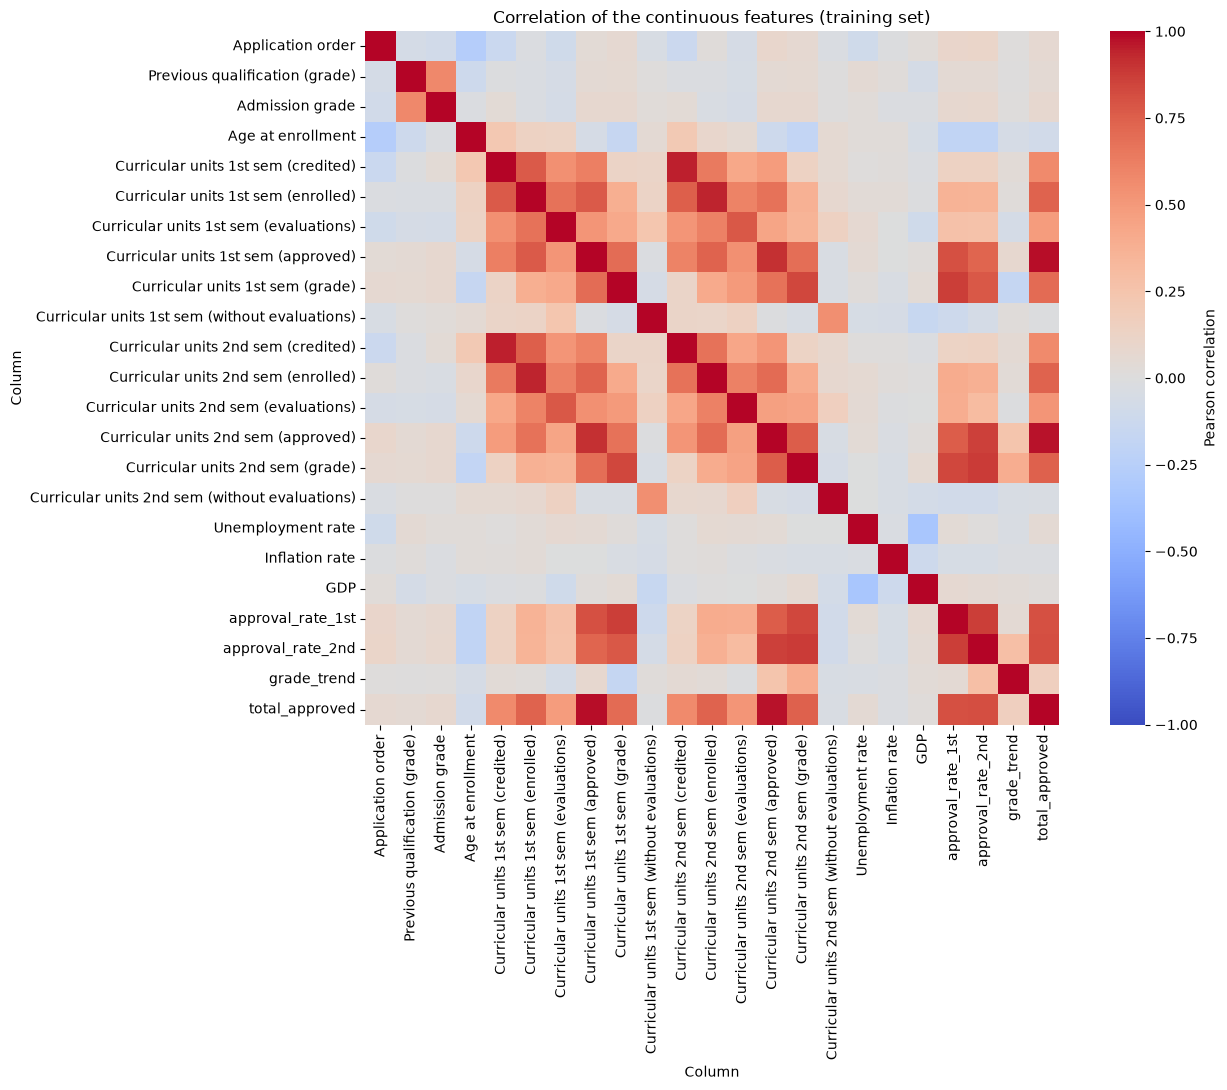

pairs with |r| > 0.7: 29


,,r
Column,Column,
Curricular units 1st sem (approved),total_approved,0.977
Curricular units 2nd sem (approved),total_approved,0.976
Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.948
Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.943
Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.907
Curricular units 2nd sem (grade),approval_rate_2nd,0.881
approval_rate_1st,approval_rate_2nd,0.874
Curricular units 1st sem (grade),approval_rate_1st,0.869
Curricular units 2nd sem (approved),approval_rate_2nd,0.867


In [13]:
import seaborn as sns

corr = X_train[CONTINUOUS_ALL].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation of the continuous features (training set)")
plt.tight_layout()
plt.show()

# each strongly correlated pair once, strongest first
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = upper[upper.abs() > 0.7].sort_values(key=abs, ascending=False)
print(f"pairs with |r| > 0.7: {len(strong)}")
strong.round(3).rename("r").to_frame()

In [14]:
from sklearn.feature_selection import chi2, mutual_info_classif

M_train = prep.transform(X_train)
f_scores, _ = f_classif(M_train, y_train)
mi_scores = mutual_info_classif(M_train, y_train, random_state=RANDOM_STATE)

screening = pd.DataFrame({"anova_f": f_scores.round(2), "mutual_info": mi_scores.round(4)},
                         index=feature_names)
screening["anova_rank"] = screening["anova_f"].rank(ascending=False).astype(int)
screening["mi_rank"] = screening["mutual_info"].rank(ascending=False).astype(int)
screening["mean_rank"] = (screening[["anova_rank", "mi_rank"]].mean(axis=1)).round(1)

# chi-square needs non-negative input: the encoded columns and the binary flags
categorical = slice(0, n_nominal + len(BINARY))
chi_scores, chi_p = chi2(M_train[:, categorical], y_train)
print(f"chi-square: {(chi_p < 0.05).sum()} of {len(chi_p)} categorical columns significant at p < 0.05\n")

print("top 15 features by average rank:")
screening.sort_values("mean_rank").head(15)

chi-square: 48 of 86 categorical columns significant at p < 0.05

top 15 features by average rank:


,anova_f,mutual_info,anova_rank,mi_rank,mean_rank
approval_rate_2nd,1705.34,0.3450,1,1,1.0
Curricular units 2nd sem (approved),1092.91,0.3141,3,2,2.5
approval_rate_1st,1135.22,0.2757,2,4,3.0
total_approved,910.34,0.3119,5,3,4.0
Curricular units 2nd sem (grade),911.94,0.2382,4,5,4.5
Curricular units 1st sem (approved),660.29,0.2351,6,6,6.0
Curricular units 1st sem (grade),573.05,0.1769,7,7,7.0
Tuition fees up to date,406.06,0.0997,8,9,8.5
Scholarship holder,176.60,0.0554,9,13,11.0
Age at enrollment,124.84,0.0650,10,12,11.0


### 3.9 Dimensionality reduction with PCA · *Kusal*

PCA replaces correlated columns with uncorrelated combinations ordered by how much variance
each explains. It is applied to the scaled continuous columns only: rotating one-hot columns
would mix unrelated categories into components nobody could interpret. The component count
is chosen here from the training rows; inside the models, PCA sits in the pipeline and is
re-fitted on every training fold.

components for 80% of the variance: 8
components for 90% of the variance: 11
components for 95% of the variance: 13
components for 99% of the variance: 17

chosen: 13 components of 23 continuous columns


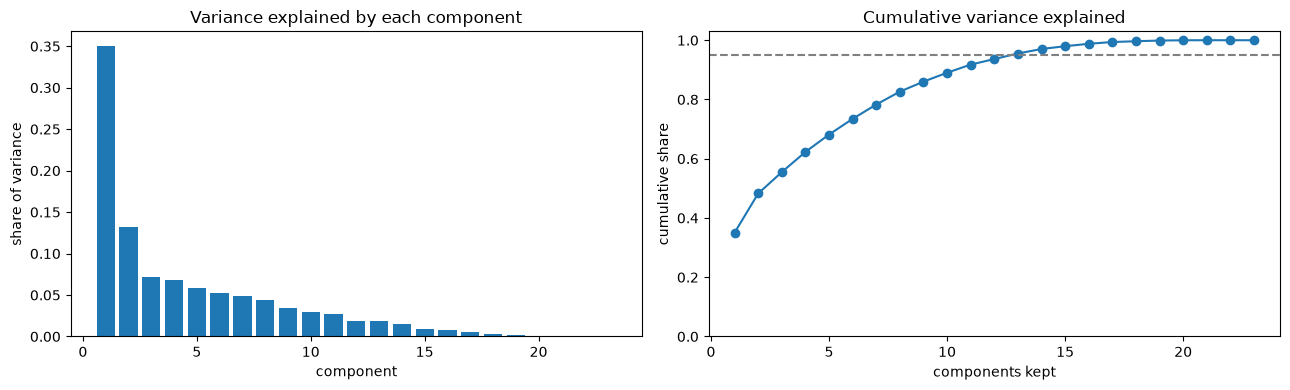

strongest loadings on the first component:


total_approved                         0.340
Curricular units 1st sem (approved)    0.336
Curricular units 2nd sem (approved)    0.327
Curricular units 1st sem (enrolled)    0.288
Curricular units 2nd sem (enrolled)    0.285
approval_rate_1st                      0.274
dtype: float64

In [15]:
pca_full = PCA(random_state=RANDOM_STATE).fit(train_scaled)
cumulative = pca_full.explained_variance_ratio_.cumsum()

for share in (0.80, 0.90, 0.95, 0.99):
    print(f"components for {share:.0%} of the variance: {int((cumulative < share).sum() + 1)}")
PCA_COMPONENTS = int((cumulative < 0.95).sum() + 1)
print(f"\nchosen: {PCA_COMPONENTS} components of {len(CONTINUOUS_ALL)} continuous columns")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
components = np.arange(1, len(cumulative) + 1)
axes[0].bar(components, pca_full.explained_variance_ratio_)
axes[0].set(title="Variance explained by each component", xlabel="component",
            ylabel="share of variance")
axes[1].plot(components, cumulative, marker="o")
axes[1].axhline(0.95, linestyle="--", color="grey")
axes[1].set(title="Cumulative variance explained", xlabel="components kept",
            ylabel="cumulative share", ylim=(0, 1.03))
plt.tight_layout()
plt.show()

loadings = pd.Series(pca_full.components_[0], index=CONTINUOUS_ALL)
print("strongest loadings on the first component:")
loadings.abs().sort_values(ascending=False).head(6).round(3)

### 3.10 The four feature variants the models use · *Lahiru, Kusal*

Both models are fitted to the same four variants, so the effect of the feature set can be
separated from the effect of the algorithm.

| variant | what it is | question it answers |
|---|---|---|
| `all` | every feature, encoded and scaled | the baseline set |
| `reduced` | the 40 strongest features by ANOVA F | does screening help, or just discard signal? |
| `pca` | continuous block replaced by its principal components | dimensionality reduction by extraction |
| `first_sem` | second-semester columns withheld | how early can a warning be issued? |

`first_sem` is about when data becomes available, not leakage: second-semester results are
the strongest predictors, but they do not exist until a student is most of a year in.

In [16]:
FIRST_SEM = [c for c in CONTINUOUS if "2nd sem" not in c] + ["approval_rate_1st"]


def build_pipeline(model, variant="all", k=40):
    """The preprocessing plus a model, for one of the four feature variants."""
    if variant == "first_sem":
        prep_step = build_preprocessor(continuous=FIRST_SEM)
    elif variant == "pca":
        prep_step = build_preprocessor(pca_components=PCA_COMPONENTS)
    else:
        prep_step = build_preprocessor()
    steps = [("prep", prep_step)]
    if variant == "reduced":
        steps.append(("select", SelectKBest(f_classif, k=k)))
    return Pipeline(steps + [("model", model)])


from sklearn.dummy import DummyClassifier

widths = {variant: build_pipeline(DummyClassifier(), variant).fit(X_train, y_train)[:-1]
          .transform(X_train).shape[1]
          for variant in ("all", "reduced", "pca", "first_sem")}
pd.Series(widths, name="features").to_frame()

,features
all,109
reduced,40
pca,99
first_sem,100


### 3.11 The baseline every model must beat · *Lahiru, Kusal*

As in Lab 03, a naive baseline comes first so later numbers mean something. A classifier that
always answers the most common class, `Graduate`, scores about 50% accuracy while identifying
no student at risk at all. That is why the models are judged on macro-F1, which counts the
three classes equally, rather than on accuracy.

In [17]:
baseline = cross_validate(DummyClassifier(strategy="most_frequent"), X_train, y_train,
                          cv=cv, scoring=["accuracy", "f1_macro"])
print(f"majority-class baseline (5-fold, training set): "
      f"accuracy {baseline['test_accuracy'].mean():.3f} | "
      f"macro-F1 {baseline['test_f1_macro'].mean():.3f}")

assert len(X_test) == 885, "the test set stays untouched until section 6"

majority-class baseline (5-fold, training set): accuracy 0.499 | macro-F1 0.222


### 3.12 Shared scoring · *Lahiru, Kusal*

Both models are scored by the same function, so their results tables have identical columns
and can be compared directly in section 6. Scores come from out-of-fold predictions: each
training row is predicted by a model fitted on the other four folds, so no row is scored by a
model that saw it. Macro-F1 leads, with balanced accuracy, MCC, ROC-AUC and the recall of each
class alongside it.

In [18]:
from sklearn.metrics import average_precision_score, balanced_accuracy_score
from sklearn.model_selection import cross_val_predict

CLASSES = ["Dropout", "Enrolled", "Graduate"]


def cv_scores(pipeline, X, y, name, variant, binary=False):
    """Cross-validated scores from out-of-fold predictions, as one row of a results table."""
    proba = cross_val_predict(pipeline, X, y, cv=cv, method="predict_proba")
    if binary:
        predicted = (proba[:, 1] >= 0.5).astype(int)
    else:
        predicted = np.unique(y)[proba.argmax(axis=1)]

    row = {
        "model": name,
        "variant": variant,
        "accuracy": accuracy_score(y, predicted),
        "balanced_accuracy": balanced_accuracy_score(y, predicted),
        "f1_macro": f1_score(y, predicted, average="macro"),
        "mcc": matthews_corrcoef(y, predicted),
    }
    if binary:
        row["roc_auc"] = roc_auc_score(y, proba[:, 1])
        row["pr_auc"] = average_precision_score(y, proba[:, 1])
        row["recall_dropout"] = recall_score(y, predicted)
    else:
        row["roc_auc"] = roc_auc_score(y, proba, multi_class="ovr", labels=np.unique(y))
        per_class = recall_score(y, predicted, average=None, labels=CLASSES)
        row.update({f"recall_{c.lower()}": r for c, r in zip(CLASSES, per_class)})
    return row

## 4. Model 1 - Linear Regression · *Lahiru*

Linear, model-based* method. We follow the  **Lab 3** workflow (baseline → fit → MSE/RMSE/R² → actual-vs-predicted
→ residuals → coefficients) and the **Lab 4** workflow (feature scaling, the cost function, gradient descent, the normal
equation, scikit-learn verification, and Ridge regularization).

**An honest design choice (Lab 3's first lesson: *inspect the target before assuming linear regression*).**
Our target has three categories — `Dropout`, `Enrolled`, `Graduate` — so plain linear regression, which predicts a
continuous number, is not a native classifier. However, the three outcomes have a **natural order of academic success**:

$$\text{Dropout}\;(0)\;<\;\text{Enrolled}\;(1)\;<\;\text{Graduate}\;(2)$$

So we treat the problem as **ordinal regression by rounding**: linear regression predicts a continuous *success score*,
which we then round and clip to the nearest class. This lets us (a) apply every Lab 3/4 technique faithfully, and
(b) compare the result with the Random Forest in Section 6. We state up front that this assumes the classes are equally
spaced and ordered — a simplification a proper classifier (logistic/softmax regression, or the forest) does not need.
We validate every result with **5-fold cross-validation on the training set only**; the test set stays untouched until
Section 6.

### 4.1 Frame the target as an ordinal success score · *Lahiru*

In [19]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_predict

# Natural order of academic success: Dropout < Enrolled < Graduate
ORDER = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}
LABELS_SORTED = np.array(["Dropout", "Enrolled", "Graduate"])     # index 0,1,2 matches ORDER

y_train_reg = y_train.map(ORDER).astype(float)                    # continuous target for regression
print("Ordinal mapping:", ORDER)
print("Success-score distribution in the training set:")
display(y_train_reg.value_counts().sort_index().rename("count").to_frame())

Ordinal mapping: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
Success-score distribution in the training set:


,count
Target,
0.0,1137
1.0,635
2.0,1767


### 4.2 A naive baseline every model must beat (Lab 3, Part C) · *Lahiru*

`DummyRegressor(strategy="mean")` predicts the mean training success score for every student. It is the regression
counterpart of the majority-class baseline used for the classifiers. Scores are cross-validated on the training set.

In [32]:
def reg_cv_predict(model, variant="all"):
    """Out-of-fold predictions of the success score (5-fold CV on the training set)."""
    pipe = build_pipeline(model, variant=variant)
    return cross_val_predict(pipe, X_train, y_train_reg, cv=cv)

baseline_oof = cross_val_predict(DummyRegressor(strategy="mean"), X_train, y_train_reg, cv=cv)
baseline_rmse = np.sqrt(mean_squared_error(y_train_reg, baseline_oof))
baseline_r2 = r2_score(y_train_reg, baseline_oof)
print(f"Mean baseline (5-fold CV):  RMSE = {baseline_rmse:.4f} | R^2 = {baseline_r2:.4f}")

Mean baseline (5-fold CV):  RMSE = 0.8882 | R^2 = -0.0000


### 4.3 Multiple linear regression with all features (Lab 3, Part D) · *Lahiru*

The model uses **all** features through the shared preprocessing pipeline (one-hot for the registry codes, pass-through
for the binary flags, standardisation for the continuous/engineered numbers — fit inside each fold, so no leakage).

In [33]:
lr_oof = reg_cv_predict(LinearRegression(), variant="all")
lr_rmse = np.sqrt(mean_squared_error(y_train_reg, lr_oof))
lr_r2 = r2_score(y_train_reg, lr_oof)
lr_mse = mean_squared_error(y_train_reg, lr_oof)

print("Linear Regression (all features, 5-fold CV on training set)")
print(f"  MSE  : {lr_mse:.4f}")
print(f"  RMSE : {lr_rmse:.4f}")
print(f"  R^2  : {lr_r2:.4f}")
print(f"  RMSE improvement over baseline: {baseline_rmse - lr_rmse:.4f}")

display(pd.DataFrame(
    {
        "RMSE": [baseline_rmse, lr_rmse], 
        "R_squared": [baseline_r2, lr_r2]
    }, 
    index=["Mean baseline", "Linear regression"]).round(4))

Linear Regression (all features, 5-fold CV on training set)
  MSE  : 0.3125
  RMSE : 0.5590
  R^2  : 0.6039
  RMSE improvement over baseline: 0.3292


,RMSE,R_squared
Mean baseline,0.8882,-0.0000
Linear regression,0.5590,0.6039


### 4.4 Diagnose the fitted model (Lab 3, Part E) · *Lahiru*

Actual-vs-predicted and residual plots use the **out-of-fold** success scores. Because the true score takes only the
values 0/1/2, the points line up in three bands — a visual reminder that we are forcing a continuous model onto ordered
categories.

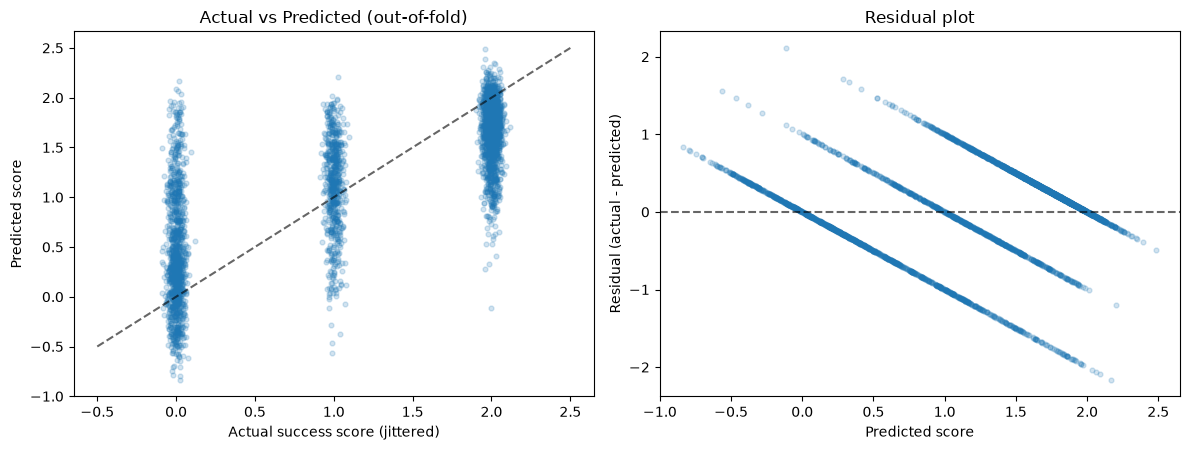

In [34]:
residuals = y_train_reg.values - lr_oof

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
# Actual vs predicted
axes[0].scatter(y_train_reg + np.random.normal(0, 0.03, len(y_train_reg)), lr_oof, alpha=0.2, s=12)
lo, hi = -0.5, 2.5
axes[0].plot([lo, hi], [lo, hi], "k--", alpha=0.6)
axes[0].set_xlabel("Actual success score (jittered)"); axes[0].set_ylabel("Predicted score")
axes[0].set_title("Actual vs Predicted (out-of-fold)")
# Residuals
axes[1].scatter(lr_oof, residuals, alpha=0.2, s=12)
axes[1].axhline(0, color="k", ls="--", alpha=0.6)
axes[1].set_xlabel("Predicted score"); axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residual plot")
plt.tight_layout(); plt.show()

### 4.5 How the parameters are obtained (Lab 4) · *Lahiru*

Lab 4 showed that the linear-regression weights can be found three equivalent ways. We reproduce that here on the
preprocessed **training** design matrix: **gradient descent** (iteratively minimise the cost `J(θ)`), the **normal
equation** (closed-form `θ = (XᵀX)⁻¹Xᵀy`), and **scikit-learn** as verification. Feature scaling (already in the
pipeline) is what lets a single learning rate work across features.

In [35]:
# --- Lab 4 cost function and gradient descent (same code as the lab) ---
def compute_cost(X, y, theta):
    m = len(y)
    error = X @ theta - y
    return float(((error.T @ error) / (2 * m)).item())

def gradient_descent(X, y, theta, alpha=0.1, iterations=500, stop_on_nonfinite=True):
    m = len(y)
    history = []
    theta = theta.astype(float).copy()
    for i in range(iterations):
        error = X @ theta - y
        gradient = (X.T @ error) / m
        theta = theta - alpha * gradient
        cost = compute_cost(X, y, theta)
        history.append(cost)
        if stop_on_nonfinite and not np.isfinite(cost):
            print(f"Stopped at iteration {i+1}: cost became non-finite."); break
    return theta, np.asarray(history)

# Build the preprocessed design matrix from the TRAINING data only (fit on train).
# The continuous features are already standardised by the pipeline; the one-hot/binary
# columns are 0/1. Gradient descent needs enough iterations to reach the closed-form optimum.
prep_lr = build_preprocessor().fit(X_train, y_train)
Xtr = prep_lr.transform(X_train).astype(float)
Xtr = np.c_[np.ones((len(Xtr), 1)), Xtr]              # add intercept column
yvec = y_train_reg.to_numpy(dtype=float).reshape(-1, 1)
theta0 = np.zeros((Xtr.shape[1], 1))
print("Design matrix:", Xtr.shape, "| initial cost:", round(compute_cost(Xtr, yvec, theta0), 4))

theta_gd, history = gradient_descent(Xtr, yvec, theta0, alpha=0.1, iterations=8000)
theta_ne = np.linalg.pinv(Xtr.T @ Xtr) @ Xtr.T @ yvec                 # normal equation

sk = LinearRegression(fit_intercept=False).fit(Xtr, yvec.ravel())     # intercept already in Xtr
pred_gd, pred_ne, pred_sk = Xtr @ theta_gd, Xtr @ theta_ne, sk.predict(Xtr).reshape(-1, 1)

print(f"Final GD cost           : {history[-1]:.4f}")
print(f"GD vs Normal-eq preds    (max abs diff): {np.max(np.abs(pred_gd - pred_ne)):.4e}")
print(f"Normal-eq vs sklearn     (max abs diff): {np.max(np.abs(pred_ne - pred_sk)):.4e}")
print(f"GD vs sklearn predictions (correlation): {np.corrcoef(pred_gd.ravel(), pred_sk.ravel())[0,1]:.5f}")
print("=> normal equation and scikit-learn match exactly; gradient descent converges to the same solution.")

Design matrix: (3539, 110) | initial cost: 1.0883
Final GD cost           : 0.1456
GD vs Normal-eq preds    (max abs diff): 1.6053e-02
Normal-eq vs sklearn     (max abs diff): 5.2069e-14
GD vs sklearn predictions (correlation): 1.00000
=> normal equation and scikit-learn match exactly; gradient descent converges to the same solution.


Stopped at iteration 146: cost became non-finite.


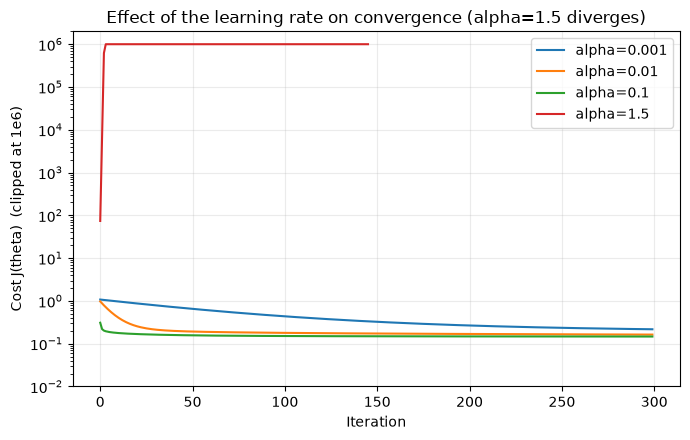

In [36]:
# Learning-rate experiment (Lab 4, A5): too-small learns slowly, too-large can diverge
CEIL = 1e6     # a diverging rate explodes to huge/inf values; clip so the log axis stays finite
plt.figure(figsize=(7, 4.5))
for a in [0.001, 0.01, 0.1, 1.5]:
    _, h = gradient_descent(Xtr, yvec, theta0, alpha=a, iterations=300)
    h = np.clip(np.nan_to_num(h, nan=CEIL, posinf=CEIL, neginf=CEIL), 1e-6, CEIL)
    plt.plot(range(len(h)), h, label=f"alpha={a}")
plt.xlabel("Iteration"); plt.ylabel("Cost J(theta)  (clipped at 1e6)"); plt.yscale("log")
plt.ylim(1e-2, CEIL * 2)
plt.title("Effect of the learning rate on convergence (alpha=1.5 diverges)")
plt.legend(); plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()

### 4.6 Ridge regularization (Lab 4, A10) · *Lahiru*

Ridge adds an L2 penalty `λ‖θ‖²` that shrinks the coefficients and reduces variance. We compare several `λ` using
cross-validated RMSE and the coefficient L2-norm (lower norm = simpler model).

In [37]:
ridge_rows = []
for lam in [0.0, 0.1, 1.0, 10.0, 100.0]:
    model = Ridge(alpha=lam, random_state=RANDOM_STATE) if lam > 0 else LinearRegression()
    oof = reg_cv_predict(model, variant="all")
    fitted = build_pipeline(Ridge(alpha=lam, random_state=RANDOM_STATE) if lam > 0 else LinearRegression()
                            ).fit(X_train, y_train_reg)
    coef_norm = np.linalg.norm(fitted.named_steps["model"].coef_)
    ridge_rows.append({"lambda": lam, "CV RMSE": np.sqrt(mean_squared_error(y_train_reg, oof)),
                       "CV R^2": r2_score(y_train_reg, oof), "coef L2 norm": coef_norm})
display(pd.DataFrame(ridge_rows).round(4))

,lambda,CV RMSE,CV R^2,coef L2 norm
0,0.0,0.5590,0.6039,1.0798
1,0.1,0.5589,0.6040,1.0778
2,1.0,0.5587,0.6043,1.0609
3,10.0,0.5574,0.6062,0.9605
4,100.0,0.5572,0.6064,0.7214


### 4.7 Which features drive the success score (Lab 3, Part F) · *Lahiru*

Coefficients from the fitted linear model (trained on the full training set). A positive weight pushes a student toward
*Graduate*; a negative weight pushes toward *Dropout*.

,Feature,Coefficient,Absolute
0,Curricular units 2nd sem (approved),0.4062,0.4062
1,Tuition fees up to date,0.4057,0.4057
2,Course_9853,-0.3385,0.3385
3,Father's occupation_infrequent_sklearn,0.2619,0.2619
4,Curricular units 2nd sem (enrolled),-0.2502,0.2502
5,total_approved,0.2356,0.2356
6,Application mode_44,0.1796,0.1796
7,Father's occupation_90,-0.1680,0.1680
8,Mother's qualification_4,0.1566,0.1566
9,Debtor,-0.1533,0.1533


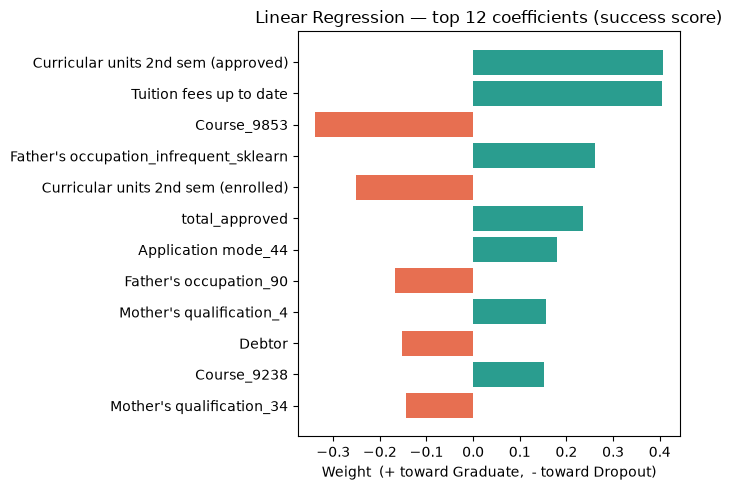

In [38]:
lin_fitted = build_pipeline(LinearRegression(), variant="all").fit(X_train, y_train_reg)
coef = pd.DataFrame({
    "Feature": lin_fitted.named_steps["prep"].get_feature_names_out(),
    "Coefficient": lin_fitted.named_steps["model"].coef_,
})
coef["Absolute"] = coef["Coefficient"].abs()
top = coef.sort_values("Absolute", ascending=False).head(12)
display(top.round(4).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#2a9d8f" if v > 0 else "#e76f51" for v in top["Coefficient"][::-1]]
ax.barh(top["Feature"][::-1], top["Coefficient"][::-1], color=colors)
ax.set_title("Linear Regression — top 12 coefficients (success score)")
ax.set_xlabel("Weight  (+ toward Graduate,  - toward Dropout)")
plt.tight_layout(); plt.show()

### 4.8 From regression to classification (comparable to Model 2) · *Lahiru*

We turn the continuous success score into a class by **rounding to the nearest integer and clipping to {0,1,2}**, then
map back to the labels. This gives classification metrics directly comparable with the Random Forest, computed from
out-of-fold predictions. We also check **training vs cross-validated accuracy** (the bias–variance view).

In [39]:
def score_to_label(score):
    return LABELS_SORTED[np.clip(np.rint(score), 0, 2).astype(int)]

def lr_classification_row(variant, label):
    oof = reg_cv_predict(LinearRegression(), variant=variant)
    pred = score_to_label(oof)
    per_class = recall_score(y_train, pred, average=None, labels=CLASSES)
    row = {"model": "Linear Regression", "variant": label,
           "accuracy": accuracy_score(y_train, pred),
           "balanced_accuracy": balanced_accuracy_score(y_train, pred),
           "f1_macro": f1_score(y_train, pred, average="macro"),
           "mcc": matthews_corrcoef(y_train, pred),
           "roc_auc": np.nan}   # plain linear regression has no class probabilities
    row.update({f"recall_{c.lower()}": r for c, r in zip(CLASSES, per_class)})
    return row

lr_results = pd.DataFrame([lr_classification_row("all", "all features"),
                           lr_classification_row("first_sem", "1st sem only")])
display(lr_results.round(4))

# Bias-variance check: training accuracy vs cross-validated accuracy (all features)
train_pred = score_to_label(build_pipeline(LinearRegression(), "all")
                            .fit(X_train, y_train_reg).predict(X_train))
train_acc = accuracy_score(y_train, train_pred)
cv_acc = accuracy_score(y_train, score_to_label(reg_cv_predict(LinearRegression(), "all")))
print(f"\nTraining accuracy        : {train_acc:.4f}")
print(f"Cross-validated accuracy : {cv_acc:.4f}")
print(f"Train - CV gap           : {train_acc - cv_acc:.4f}  (small gap => low variance / stable)")

,model,variant,accuracy,balanced_accuracy,f1_macro,mcc,roc_auc,recall_dropout,recall_enrolled,recall_graduate
0,Linear Regression,all features,0.7053,0.6862,0.6723,0.5605,NaN,0.6148,0.6661,0.7776
1,Linear Regression,1st sem only,0.6392,0.6300,0.6147,0.4788,NaN,0.5303,0.6567,0.7029



Training accuracy        : 0.7186
Cross-validated accuracy : 0.7053
Train - CV gap           : 0.0133  (small gap => low variance / stable)


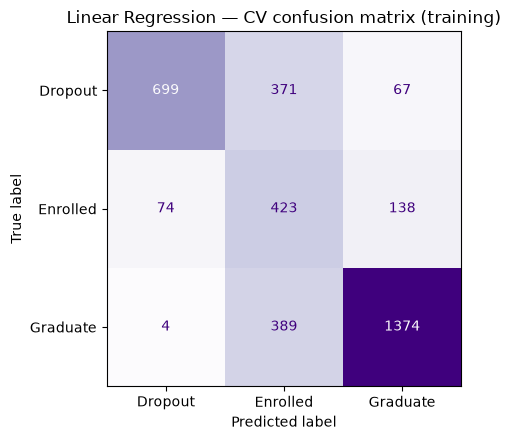

              precision    recall  f1-score   support

     Dropout     0.8996    0.6148    0.7304      1137
    Enrolled     0.3576    0.6661    0.4653       635
    Graduate     0.8702    0.7776    0.8213      1767

    accuracy                         0.7053      3539
   macro avg     0.7091    0.6862    0.6723      3539
weighted avg     0.7877    0.7053    0.7282      3539



In [40]:
# Confusion matrix from out-of-fold predictions (all features)
oof_pred = score_to_label(reg_cv_predict(LinearRegression(), "all"))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_train, oof_pred, labels=CLASSES,
                                        cmap="Purples", ax=ax, colorbar=False)
ax.set_title("Linear Regression — CV confusion matrix (training)")
plt.tight_layout(); plt.show()
print(classification_report(y_train, oof_pred, labels=CLASSES, digits=4))

### 4.9 What Linear Regression model shows, and its limitations · *Lahiru*

- **It beats the baseline.** 
  Linear regression cuts RMSE well below the mean predictor and explains a sizeable share of the variance in the success score, and the gradient-descent / normal-equation / scikit-learn solutions agree the  parameters are being learned correctly.
  
- **As a classifier it is a reasonable but limited baseline.** Rounding the score gives a usable accuracy/macro-F1, and a **small train-vs-CV gap** shows it is stable (low variance, slight underfitting  the expected behaviour of a linear model, per the bias–variance note in the lecture material). The *Enrolled* (middle) class is hardest, because the rounding boundaries around 1 are narrow and *Enrolled* overlaps both neighbours.


**Ridge note.** The Ridge experiment shows how the L2 penalty shrinks the coefficient norm; since the linear model is already low-variance here, heavy regularization mainly trades a little fit for a simpler model rather than fixing overfitting.

## 5. Model 2 - Random Forest

Model 2 is the Random Forest. It is tuned by cross-validation on the training set and run on
the four feature variants from section 3.10. The test set is not used here; every number in
this section is cross-validated on the 3,539 training rows, and the test set is opened once,
in section 6.

### 5.1 How a Random Forest works · *Kusal*

**A single decision tree** splits the data one feature at a time. At each node it searches
every feature and every threshold for the split that best separates the classes, measured by
the reduction in **Gini impurity**:

$$G = 1 - \sum_{k} p_k^2$$

where $p_k$ is the proportion of class $k$ at that node. A node containing only dropouts has
$G = 0$; one split evenly across all three outcomes has $G \approx 0.67$. The tree keeps
splitting until its leaves are pure or a stopping rule intervenes.

**The problem is variance.** Grown without limit, a tree isolates individual students, ending
with leaves that each hold one person, perfectly classified. Such a tree memorises the training
set and generalises badly, because the splits deep in the tree follow noise rather than
anything repeatable. Section 5.2 measures this directly.

**Bagging** addresses it by averaging. Many bootstrap samples are drawn, each the same size as
the training set and sampled with replacement, so roughly 37% of rows are left out of each. A
tree is fitted to each sample and the trees vote. Individual trees still overfit their own
sample, but their errors are partly independent, so averaging cancels some of them.

**Random Forest adds a second source of randomness.** At each split, a tree may only consider a
random subset of features. Without this, every tree would pick the same dominant feature at
the root (here almost certainly a second-semester approval column), and the trees would be
highly correlated, which limits how much averaging can help.

### 5.2 Why not a single tree · *Kusal*

The claim that one tree overfits is easy to check: fit an unrestricted tree and compare its
training accuracy with its cross-validated accuracy, then do the same for a forest.

In [20]:
tree = build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), variant="all")
tree.fit(X_train, y_train)
tree_train = tree.score(X_train, y_train)
tree_cv = cross_val_score(tree, X_train, y_train, cv=cv, scoring="accuracy").mean()

# same data and pipeline, 300 trees instead of one
forest = build_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE,
                                               n_jobs=-1), variant="all")
forest.fit(X_train, y_train)
forest_train = forest.score(X_train, y_train)
forest_cv = cross_val_score(forest, X_train, y_train, cv=cv, scoring="accuracy").mean()

print(f"unrestricted tree: {tree.named_steps['model'].get_n_leaves()} leaves, "
      f"depth {tree.named_steps['model'].get_depth()}")
comparison = pd.DataFrame({
    "training accuracy": [tree_train, forest_train],
    "cross-validated accuracy": [tree_cv, forest_cv],
}, index=["single tree", "random forest (300)"])
comparison["overfitting gap"] = comparison["training accuracy"] - comparison["cross-validated accuracy"]
comparison.round(4)

unrestricted tree: 630 leaves, depth 30


,training accuracy,cross-validated accuracy,overfitting gap
single tree,1.0,0.6807,0.3193
random forest (300),1.0,0.7765,0.2235


Both reach near-perfect training accuracy, so neither is underfitting. The difference is what
happens on unseen rows: the forest's cross-validated accuracy is much higher while its
training accuracy is the same. That gap is variance, and averaging over 300 decorrelated trees
is what reduces it. The forest still overfits, only less.

#### 5.2.1 Can a single tree be controlled instead?

Nobody would deploy an unrestricted tree, so the fair question is whether a pruned one closes
the gap. Limiting `max_depth` is the standard way to stop a tree memorising its training rows.
The sweep below fits one tree per depth, and then compares the two split criteria from Lab 06,
Gini and entropy, at the best depth.

In [21]:
rows = []
for depth in [2, 3, 4, 5, 6, 8, 10, 15, None]:
    pruned = build_pipeline(DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))
    scores = cross_validate(pruned, X_train, y_train, cv=cv,
                            scoring=["accuracy", "f1_macro"], return_train_score=True)
    rows.append({
        "max_depth": "None" if depth is None else depth,
        "train accuracy": scores["train_accuracy"].mean(),
        "cv accuracy": scores["test_accuracy"].mean(),
        "cv macro-F1": scores["test_f1_macro"].mean(),
    })

depth_sweep = pd.DataFrame(rows).set_index("max_depth")
depth_sweep["gap"] = depth_sweep["train accuracy"] - depth_sweep["cv accuracy"]
best_depth = depth_sweep["cv macro-F1"].idxmax()
print("best single-tree depth by cross-validated macro-F1:", best_depth)
depth_sweep.round(4)

best single-tree depth by cross-validated macro-F1: 4


,train accuracy,cv accuracy,cv macro-F1,gap
max_depth,,,,
2,0.7224,0.7211,0.5218,0.0013
3,0.7476,0.7358,0.6680,0.0118
4,0.7618,0.7488,0.6760,0.0130
5,0.7869,0.7516,0.6743,0.0353
6,0.8060,0.7454,0.6645,0.0606
8,0.8555,0.7364,0.6642,0.1192
10,0.9070,0.7259,0.6535,0.1811
15,0.9708,0.6996,0.6323,0.2711
None,1.0000,0.6807,0.6229,0.3193


In [22]:
depth_value = None if best_depth == "None" else int(best_depth)
criteria = {}
for criterion in ["gini", "entropy"]:
    candidate = build_pipeline(DecisionTreeClassifier(max_depth=depth_value, criterion=criterion,
                                                      random_state=RANDOM_STATE))
    s = cross_validate(candidate, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"])
    criteria[criterion] = {"cv accuracy": s["test_accuracy"].mean(),
                           "cv macro-F1": s["test_f1_macro"].mean()}
pd.DataFrame(criteria).T.round(4)

,cv accuracy,cv macro-F1
gini,0.7488,0.6760
entropy,0.7457,0.6818


#### 5.2.2 What the tree decides first

A depth-3 tree is small enough to read. Its root split is the single question that best
separates the outcomes. Continuous columns are standardised inside the pipeline, so the root
threshold is converted back to its original units; the rule list and the plot keep the
standardised values, in standard deviations from the mean.

root rule: approval_rate_2nd <= 0.774

|--- approval_rate_2nd <= 0.30
|   |--- approval_rate_2nd <= -1.13
|   |   |--- Curricular units 1st sem (enrolled) <= -2.31
|   |   |   |--- class: Graduate
|   |   |--- Curricular units 1st sem (enrolled) >  -2.31
|   |   |   |--- class: Dropout
|   |--- approval_rate_2nd >  -1.13
|   |   |--- Tuition fees up to date <= 0.50
|   |   |   |--- class: Dropout
|   |   |--- Tuition fees up to date >  0.50
|   |   |   |--- class: Enrolled
|--- approval_rate_2nd >  0.30
|   |--- approval_rate_2nd <= 0.53
|   |   |--- Tuition fees up to date <= 0.50
|   |   |   |--- class: Dropout
|   |   |--- Tuition fees up to date >  0.50
|   |   |   |--- class: Graduate
|   |--- approval_rate_2nd >  0.53
|   |   |--- Tuition fees up to date <= 0.50
|   |   |   |--- class: Dropout
|   |   |--- Tuition fees up to date >  0.50
|   |   |   |--- class: Graduate



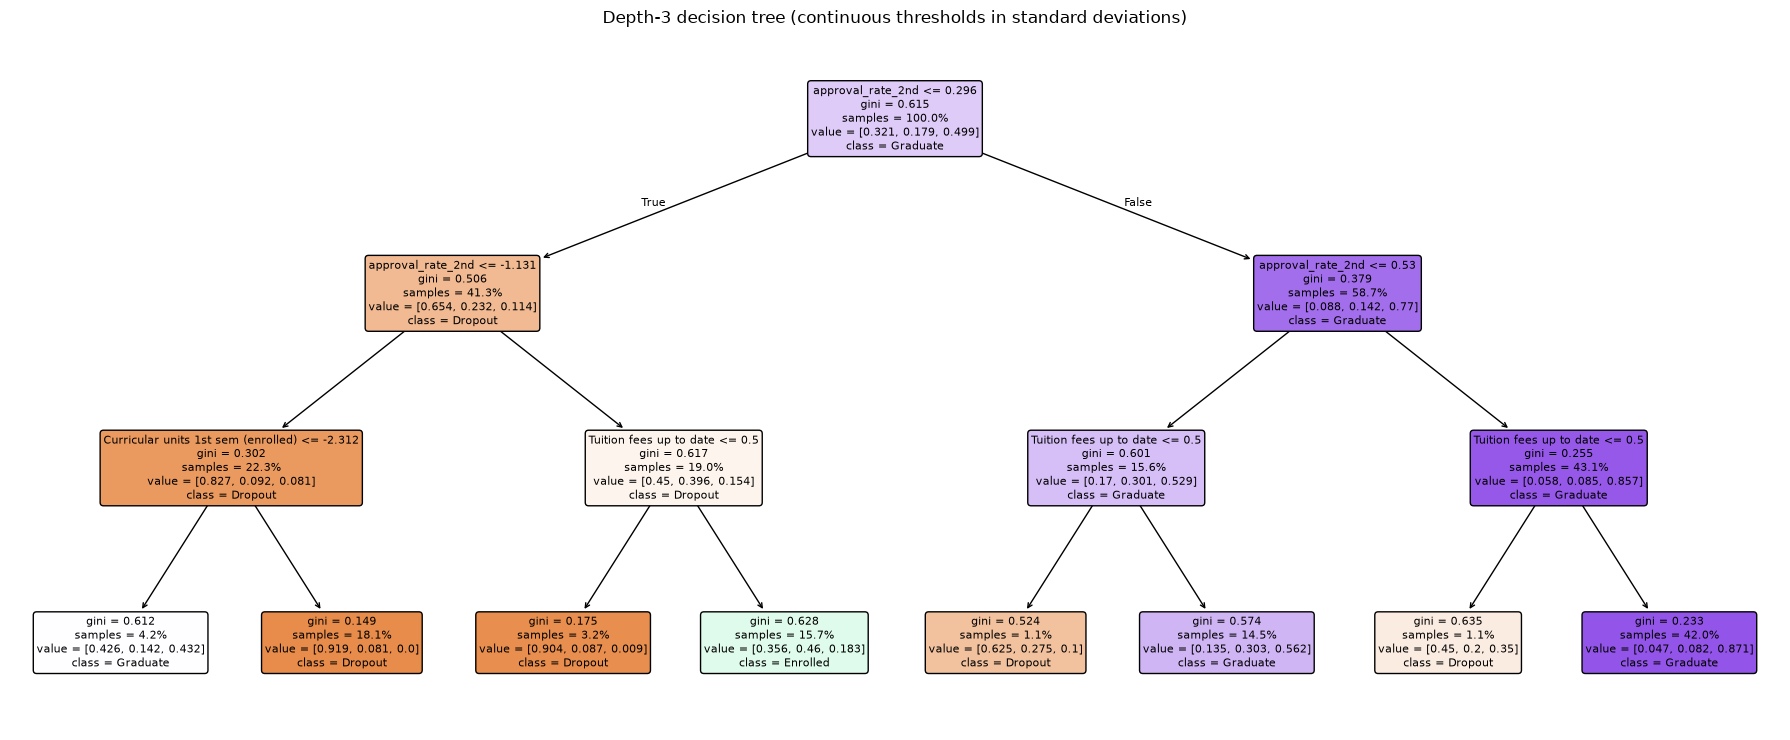

In [23]:
from sklearn.tree import export_text, plot_tree

small = build_pipeline(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))
small.fit(X_train, y_train)

tree_prep = small.named_steps["prep"]
tree_model = small.named_steps["model"]
tree_names = list(tree_prep.get_feature_names_out())
tree_scaler = tree_prep.named_transformers_["continuous"].named_steps["scale"]


def original_units(feature, threshold):
    # undo the standardisation so the rule reads in the column's own units
    if feature in CONTINUOUS_ALL:
        j = CONTINUOUS_ALL.index(feature)
        return threshold * tree_scaler.scale_[j] + tree_scaler.mean_[j]
    return threshold


root_feature = tree_names[tree_model.tree_.feature[0]]
print(f"root rule: {root_feature} <= "
      f"{original_units(root_feature, tree_model.tree_.threshold[0]):.3f}\n")
print(export_text(tree_model, feature_names=tree_names, max_depth=3))

fig, ax = plt.subplots(figsize=(18, 7.5))
plot_tree(tree_model, feature_names=tree_names, class_names=list(tree_model.classes_),
          filled=True, rounded=True, proportion=True, fontsize=8, ax=ax)
ax.set_title("Depth-3 decision tree (continuous thresholds in standard deviations)")
plt.tight_layout()
plt.show()

**Pruning helps a lot, but not enough.** Capping the tree at depth 4 cuts the overfitting gap
from about 0.32 to about 0.01 and lifts cross-validated accuracy from 0.68 to 0.75, but the
forest stays ahead. A shallow tree has too few questions to separate three overlapping
classes, and a deep tree overfits; the forest avoids the choice by growing deep trees and
averaging away their variance. Gini and entropy finish within a few thousandths of each other,
the usual result from Lab 06.

The root split is on `approval_rate_2nd`, at roughly 77% of second-semester units passed, the
feature ranked first by both ANOVA and mutual information in section 3.8. Below it, `Tuition fees up to date` decides
three of the four next splits. A student with a middling approval rate whose fees are paid lands in
`Enrolled`; the same student with unpaid fees lands in `Dropout`.

### 5.3 Why a Random Forest suits this dataset · *Kusal*

**The features are mixed in type and scale.** Trees split on one feature at a time, so they are
indifferent to `Age at enrollment` running 17 to 70 while `approval_rate_1st` runs 0 to 1.

**The relationships are not monotonic.** Section 3.8 found features that mutual information
ranks far higher than the ANOVA F-test, such as `grade_trend`, which points to relationships
that are not straight lines. A linear model needs manual interaction terms for these; a tree
captures them by construction.

**Interactions matter and are not known in advance.** Whether a low approval rate predicts
dropout plausibly depends on fees, course and attendance pattern, and a forest finds such
combinations without being told where to look.

**It gives a second, independent view of feature importance**, from inside a fitted model
rather than one feature at a time. Section 5.6 compares the two.

The counterweight is interpretability: a Logistic Regression coefficient states the direction
and size of an effect, and 300 trees do not.

### 5.4 Tuning · *Kusal*

`GridSearchCV` over the 5 stratified folds of the training set, scored on macro-F1 so that
`Enrolled`, the smallest and hardest class, counts as much as `Graduate`. Every trial is logged.
`class_weight` is part of the grid rather than fixed: `balanced` reweights classes by inverse
frequency, and `balanced_subsample` recomputes those weights for each bootstrap sample.

In [24]:
grid = {
    "model__n_estimators": [300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.3],
    "model__class_weight": [None, "balanced", "balanced_subsample"],
}
search = GridSearchCV(
    build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    param_grid=grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True,
)
search.fit(X_train, y_train)

print(f"combinations tried: {len(search.cv_results_['params'])}")
print(f"best macro-F1     : {search.best_score_:.4f}")
for key, value in sorted(search.best_params_.items()):
    print(f"  {key.replace('model__', ''):18s} {value}")

# trial log, best first
grid_results = pd.DataFrame(search.cv_results_)
log = grid_results[[c for c in grid_results.columns if c.startswith("param_model__")]
                   + ["mean_test_score", "std_test_score"]]
log.columns = [c.replace("param_model__", "") for c in log.columns]
log.sort_values("mean_test_score", ascending=False).round(4).reset_index(drop=True).head(10)

combinations tried: 54
best macro-F1     : 0.7259
  class_weight       balanced
  max_depth          None
  max_features       sqrt
  min_samples_leaf   2
  n_estimators       300


,class_weight,max_depth,max_features,min_samples_leaf,n_estimators,mean_test_score,std_test_score
0,balanced,None,sqrt,2,300,0.7259,0.0145
1,balanced,20,sqrt,1,300,0.7242,0.0181
2,balanced,None,sqrt,1,300,0.7231,0.0157
3,balanced_subsample,10,sqrt,1,300,0.7221,0.0184
4,balanced,10,0.3,2,300,0.7215,0.0194
5,balanced,10,sqrt,1,300,0.7214,0.0155
6,balanced,20,sqrt,2,300,0.7212,0.0126
7,balanced,10,sqrt,2,300,0.7207,0.0144
8,balanced,20,0.3,1,300,0.7205,0.0156
9,balanced_subsample,None,sqrt,5,300,0.7204,0.0132


In [25]:
# how much each parameter matters on its own; keys come from cv_results_["params"] because
# the param_ columns turn None into NaN, which groupby would drop silently
for parameter in ["model__max_depth", "model__min_samples_leaf",
                  "model__max_features", "model__class_weight"]:
    keys = [str(p[parameter]) for p in search.cv_results_["params"]]
    effect = (grid_results.assign(setting=keys).groupby("setting")["mean_test_score"]
              .agg(["mean", "max"]).round(4).sort_values("mean", ascending=False))
    print(f"{parameter.replace('model__', '')}:\n{effect.to_string()}\n")

max_depth:
           mean     max
setting                
20       0.7066  0.7242
10       0.7064  0.7221
None     0.7062  0.7259

min_samples_leaf:
           mean     max
setting                
2        0.7072  0.7259
1        0.7070  0.7242
5        0.7051  0.7204

max_features:
           mean     max
setting                
0.3      0.7077  0.7215
sqrt     0.7052  0.7259

class_weight:
                      mean     max
setting                           
balanced            0.7199  0.7259
balanced_subsample  0.7130  0.7221
None                0.6863  0.7012



Only `class_weight` makes a real difference. Depth, leaf size and feature-subset size each move
the mean score by a few thousandths, because averaging 300 trees already controls the variance
that limiting depth would control. The imbalance, not the capacity, was the thing worth tuning.

### 5.5 The four feature variants · *Kusal*

The tuned settings are reused on all four variants, so the only thing changing between rows is
the feature set.

In [26]:
best = search.best_params_


def best_forest(**overrides):
    """The tuned forest, with named parameters overridden."""
    params = {key.replace("model__", ""): value for key, value in best.items()}
    params.update(random_state=RANDOM_STATE, n_jobs=-1, **overrides)
    return RandomForestClassifier(**params)


VARIANTS = {"all": "all features", "reduced": "reduced", "pca": "pca", "first_sem": "1st sem only"}
rf_results = pd.DataFrame([
    cv_scores(build_pipeline(best_forest(), variant), X_train, y_train,
              name="Random Forest", variant=label)
    for variant, label in VARIANTS.items()
])
rf_results.round(4)

,model,variant,accuracy,balanced_accuracy,f1_macro,mcc,roc_auc,recall_dropout,recall_enrolled,recall_graduate
0,Random Forest,all features,0.7720,0.7273,0.7260,0.6322,0.8912,0.7449,0.5780,0.8591
1,Random Forest,reduced,0.7609,0.7155,0.7133,0.6157,0.8857,0.7353,0.5622,0.8489
2,Random Forest,pca,0.7669,0.7120,0.7155,0.6191,0.8835,0.7520,0.5181,0.8659
3,Random Forest,1st sem only,0.7480,0.6973,0.6979,0.5912,0.8714,0.7265,0.5228,0.8427


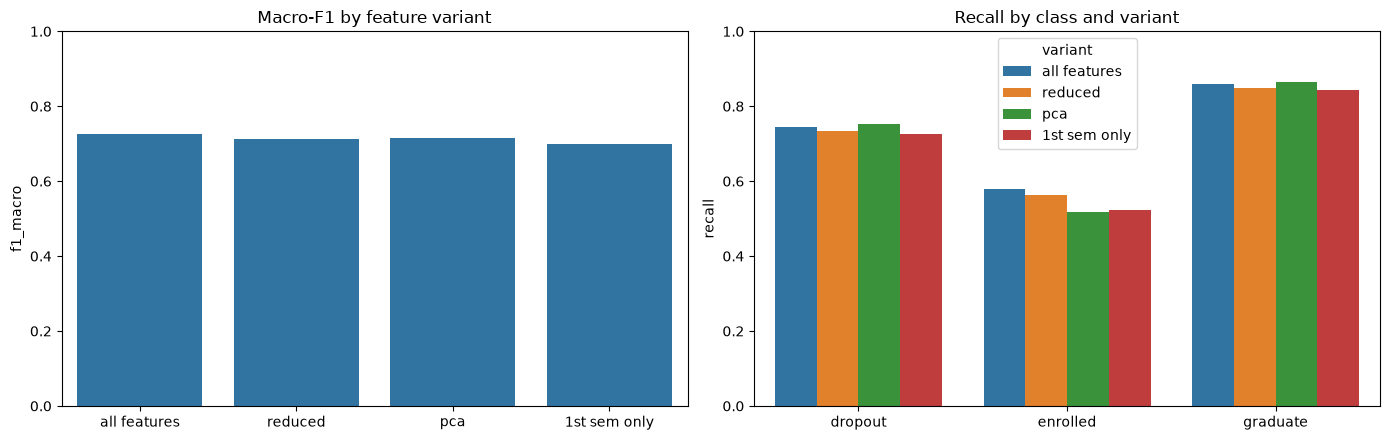

row percentages:
predicted  Dropout  Enrolled  Graduate
true                                  
Dropout       74.5      15.4      10.1
Enrolled      16.1      57.8      26.1
Graduate       2.9      11.2      85.9


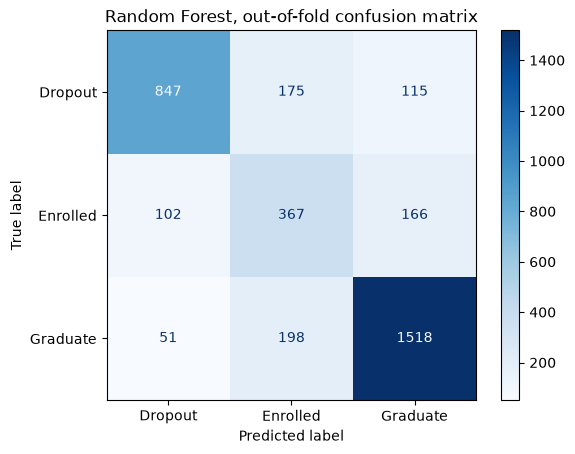

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=rf_results, x="variant", y="f1_macro", ax=axes[0])
axes[0].set(title="Macro-F1 by feature variant", xlabel="", ylim=(0, 1))

per_class = rf_results.melt(id_vars="variant",
                            value_vars=["recall_dropout", "recall_enrolled", "recall_graduate"],
                            var_name="class", value_name="recall")
per_class["class"] = per_class["class"].str.replace("recall_", "")
sns.barplot(data=per_class, x="class", y="recall", hue="variant", ax=axes[1])
axes[1].set(title="Recall by class and variant", xlabel="", ylim=(0, 1))
plt.tight_layout()
plt.show()

# out-of-fold confusion matrix for the all-features forest
predicted = cross_val_predict(build_pipeline(best_forest()), X_train, y_train, cv=cv)
matrix = pd.DataFrame(confusion_matrix(y_train, predicted, labels=CLASSES),
                      index=pd.Index(CLASSES, name="true"),
                      columns=pd.Index(CLASSES, name="predicted"))
print("row percentages:")
print((matrix.div(matrix.sum(axis=1), axis=0) * 100).round(1))
ConfusionMatrixDisplay(matrix.to_numpy(), display_labels=CLASSES).plot(cmap="Blues")
plt.title("Random Forest, out-of-fold confusion matrix")
plt.show()

Neither form of reduction helps: PCA and ANOVA selection each cost about a point of macro-F1.
PCA gives the best dropout recall of the four and the worst `Enrolled` recall, which is what an
unsupervised method that maximises variance without looking at the target would be expected to
do. In the confusion matrix, about a quarter of `Enrolled` students are predicted to graduate:
the model is systematically optimistic about the students who are behind schedule.

### 5.6 Which features the forest used · *Kusal*

`feature_importances_` is the total reduction in Gini impurity attributable to each feature,
averaged over the 300 trees. It favours features with many possible split points, such as
continuous columns. One-hot encoding pulls the other way: a category's importance is spread
across its separate columns, so the ranking adds those columns back together for each
original feature before comparing it with section 3.8 and the descriptor paper's five most
important features.

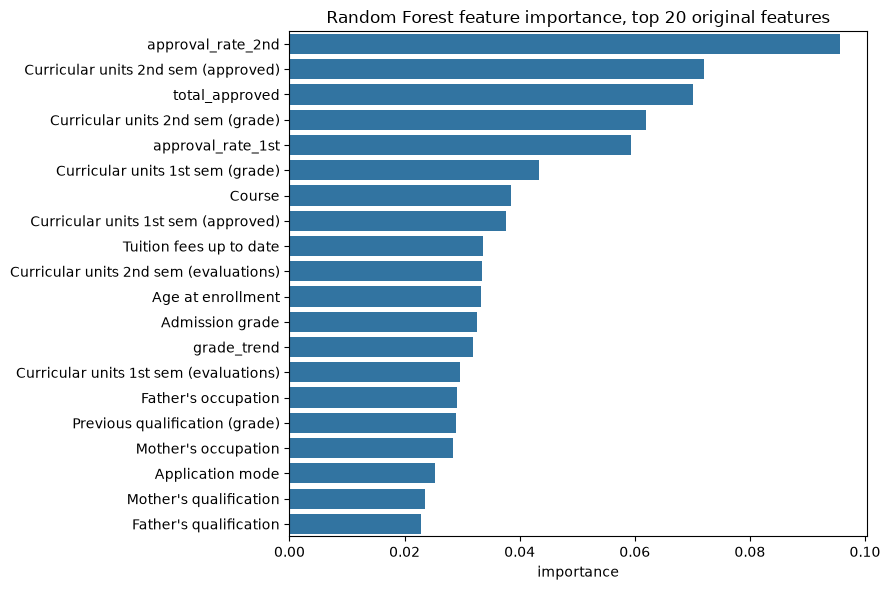

the paper's five features and the four engineered ones, as ranked by the forest:
  Curricular units 2nd sem (approved)    rank  2 of 39  importance 0.0721
  Curricular units 1st sem (approved)    rank  8 of 39  importance 0.0377
  Curricular units 2nd sem (grade)       rank  4 of 39  importance 0.0619
  Course                                 rank  7 of 39  importance 0.0384
  Tuition fees up to date                rank  9 of 39  importance 0.0336
  approval_rate_1st                      rank  5 of 39  importance 0.0593
  approval_rate_2nd                      rank  1 of 39  importance 0.0956
  grade_trend                            rank 13 of 39  importance 0.0320
  total_approved                         rank  3 of 39  importance 0.0702

encoded columns with effectively zero importance: 10 of 109


In [36]:
fitted = build_pipeline(best_forest()).fit(X_train, y_train)
column_importance = pd.Series(fitted.named_steps["model"].feature_importances_,
                              index=fitted.named_steps["prep"].get_feature_names_out())


def original_feature(column):
    # one-hot columns such as "Course_9853" belong to the original "Course" feature
    return next((name for name in NOMINAL if column.startswith(name + "_")), column)


importance = (column_importance.groupby(original_feature).sum()
              .sort_values(ascending=False).rename("importance").to_frame())
importance["rank"] = np.arange(1, len(importance) + 1)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=importance["importance"].head(20), y=importance.index[:20], ax=ax)
ax.set(title="Random Forest feature importance, top 20 original features",
       xlabel="importance", ylabel="")
plt.tight_layout()
plt.show()

paper_five = ["Curricular units 2nd sem (approved)", "Curricular units 1st sem (approved)",
              "Curricular units 2nd sem (grade)", "Course", "Tuition fees up to date"]
print("the paper's five features and the four engineered ones, as ranked by the forest:")
for name in paper_five + ENGINEERED:
    print(f"  {name:38s} rank {importance.loc[name, 'rank']:2d} of {len(importance)}"
          f"  importance {importance.loc[name, 'importance']:.4f}")
print(f"\nencoded columns with effectively zero importance: "
      f"{int((column_importance < 0.0005).sum())} of {len(column_importance)}")


Three of the top five are the engineered features, with the second-semester approval rate
first. `Course` looks unimportant as separate one-hot columns, but once its columns are added
together it ranks among the top ten, in line with the descriptor paper.


### 5.7 How early can a warning be issued? · *Kusal*

The `first_sem` variant withholds every second-semester column. Second-semester results are
the strongest predictors, but they do not exist until a student is most of a year in, so the
difference between the two rows below is what accuracy costs to act a semester sooner.

In [29]:
early = rf_results.set_index("variant").loc[["all features", "1st sem only"],
        ["accuracy", "balanced_accuracy", "f1_macro", "mcc", "roc_auc",
         "recall_dropout", "recall_enrolled", "recall_graduate"]].T
early["change"] = early["1st sem only"] - early["all features"]
early.round(4)

variant,all features,1st sem only,change
accuracy,0.7720,0.7480,-0.0240
balanced_accuracy,0.7273,0.6973,-0.0300
f1_macro,0.7260,0.6979,-0.0280
mcc,0.6322,0.5912,-0.0410
roc_auc,0.8912,0.8714,-0.0198
recall_dropout,0.7449,0.7265,-0.0185
recall_enrolled,0.5780,0.5228,-0.0551
recall_graduate,0.8591,0.8427,-0.0164


Acting a semester earlier costs about three points of macro-F1 but under two points of
dropout recall; the largest loss falls on `Enrolled`. The early model keeps nearly all of its
ability to do the job it exists for.

### 5.8 Binary framing: Dropout vs rest · *Kusal*

Collapsing the outcomes to Dropout against everything else matches how a student support office
would use the model, as a list of students to contact. The tuned forest is reused with its class
weights and scored on the binary task; average precision (PR-AUC) is the headline here because
Dropout is the minority class at 32.1%.

In [30]:
yb_train = (y_train == "Dropout").astype(int)
rf_binary = cv_scores(build_pipeline(best_forest()), X_train, yb_train,
                      name="Random Forest", variant="all features", binary=True)
pd.Series({k: round(v, 4) if isinstance(v, float) else v for k, v in rf_binary.items()}).to_frame("Random Forest, Dropout vs rest")

,"Random Forest, Dropout vs rest"
model,Random Forest
variant,all features
accuracy,0.8627
balanced_accuracy,0.8442
f1_macro,0.8431
mcc,0.6862
roc_auc,0.9218
pr_auc,0.8769
recall_dropout,0.7924


### 5.9 Summary · *Kusal*

Everything in this section is cross-validated on the training set. The tuned settings and the
results table are kept for section 6, where the test set is used for the first time.

In [31]:
print("Random Forest, 5-fold cross-validation on 3,539 training rows\n")
print(rf_results.set_index("variant")[["f1_macro", "balanced_accuracy", "mcc",
                                       "recall_dropout", "recall_enrolled"]]
      .sort_values("f1_macro", ascending=False).round(4).to_string())

rf_params = {key.replace("model__", ""): value for key, value in best.items()}
print("\ntuned Random Forest:", rf_params)

assert len(X_test) == 885, "the test set stays untouched until section 6"

Random Forest, 5-fold cross-validation on 3,539 training rows

              f1_macro  balanced_accuracy     mcc  recall_dropout  recall_enrolled
variant                                                                           
all features    0.7260             0.7273  0.6322          0.7449           0.5780
pca             0.7155             0.7120  0.6191          0.7520           0.5181
reduced         0.7133             0.7155  0.6157          0.7353           0.5622
1st sem only    0.6979             0.6973  0.5912          0.7265           0.5228

tuned Random Forest: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 300}


## 6. Model Comparison & Evaluation

Model 1 (Linear Regression) and Model 2 (Random Forest) have each been developed and cross-validated on the  **training set only**. Following the **Lab 8** workflow for *evaluation, class imbalance, validation and model selection*, this section (1) selects the final model using cross-validation, (2) studies class-imbalance handling, (3) evaluates the selected models **once** on the untouched test set, and (4) looks at an operational early-warning operating point. The guiding rule from the lectures and Lab 8: **accuracy alone is misleading under class imbalance, and the test set must stay untouched until every modelling choice is fixed.**

### 6.1 Model selection — fair cross-validation comparison · *Lahiru, Kusal*

,model,variant,accuracy,balanced_accuracy,f1_macro,mcc,roc_auc,recall_dropout,recall_enrolled,recall_graduate
0,Random Forest,all features,0.7720,0.7273,0.7260,0.6322,0.8912,0.7449,0.5780,0.8591
1,Random Forest,pca,0.7669,0.7120,0.7155,0.6191,0.8835,0.7520,0.5181,0.8659
2,Random Forest,reduced,0.7609,0.7155,0.7133,0.6157,0.8857,0.7353,0.5622,0.8489
3,Random Forest,1st sem only,0.7480,0.6973,0.6979,0.5912,0.8714,0.7265,0.5228,0.8427
4,Linear Regression,all features,0.7053,0.6862,0.6723,0.5605,NaN,0.6148,0.6661,0.7776
5,Linear Regression,1st sem only,0.6392,0.6300,0.6147,0.4788,NaN,0.5303,0.6567,0.7029


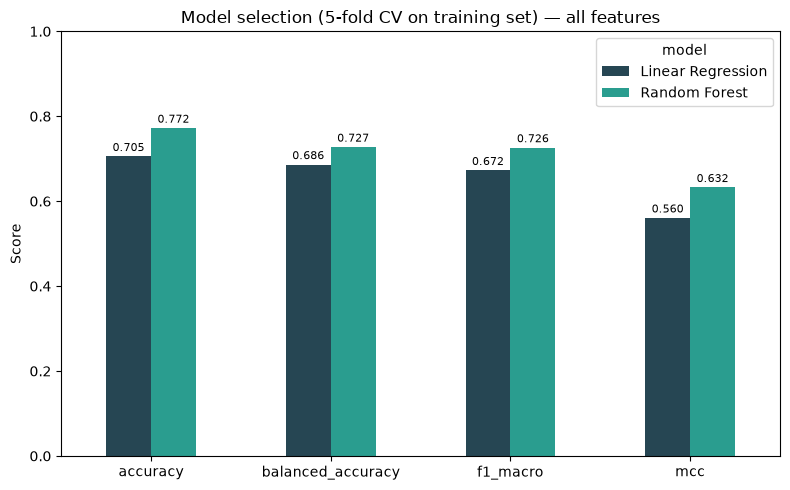

Selected model (highest CV macro-F1): Random Forest


In [41]:
# Reuse the cross-validated results already computed for each model (same splits, same metrics).
compare_cols = ["model", "variant", "accuracy", "balanced_accuracy", "f1_macro", "mcc",
                "roc_auc", "recall_dropout", "recall_enrolled", "recall_graduate"]
cv_compare = pd.concat([lr_results, rf_results], ignore_index=True)[compare_cols]
display(cv_compare.sort_values("f1_macro", ascending=False).round(4).reset_index(drop=True))

# headline comparison on the best "all features" variant of each model
best_rows = (cv_compare[cv_compare["variant"] == "all features"]
             .set_index("model")[["accuracy", "balanced_accuracy", "f1_macro", "mcc"]])
ax = best_rows.T.plot(kind="bar", figsize=(8, 5), color=["#264653", "#2a9d8f"])
ax.set_title("Model selection (5-fold CV on training set) — all features")
ax.set_ylabel("Score"); ax.set_ylim(0, 1); ax.set_xticklabels(best_rows.columns, rotation=0)
ax.legend(title="model")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout(); plt.show()

selected = cv_compare.sort_values("f1_macro", ascending=False).iloc[0]["model"]
print("Selected model (highest CV macro-F1):", selected)

Random Forest wins on every cross-validated metric  accuracy, balanced accuracy, macro-F1 and MCC , so it is our  **selected model**. Linear Regression, with its ordinal-rounding trick, is a stable but weaker baseline, exactly as the bias–variance discussion predicted: a linear decision surface cannot separate three overlapping outcome groups as well  as a non-linear ensemble.

### 6.2 Handling class imbalance (Lab 8, Part B) · *Lahiru*

In [42]:
# The middle class 'Enrolled' is the minority; compare three imbalance strategies for the forest,
# scored with the same stratified CV on the training set. SMOTE is applied INSIDE the pipeline
# (training folds only) so no information leaks across folds.
from sklearn.model_selection import cross_val_predict

def imbalance_row(name, estimator, use_smote=False):
    if use_smote:
        try:
            from imblearn.pipeline import Pipeline as ImbPipeline
            from imblearn.over_sampling import SMOTE
        except Exception as e:
            print("imbalanced-learn not available, skipping SMOTE:", e); return None
        pipe = ImbPipeline([("prep", build_preprocessor()),
                            ("smote", SMOTE(random_state=RANDOM_STATE)),
                            ("model", estimator)])
    else:
        pipe = build_pipeline(estimator, variant="all")
    pred = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict")
    rec = recall_score(y_train, pred, average=None, labels=CLASSES)
    return {"strategy": name,
            "f1_macro": f1_score(y_train, pred, average="macro"),
            "balanced_accuracy": balanced_accuracy_score(y_train, pred),
            "recall_dropout": rec[0], "recall_enrolled": rec[1], "recall_graduate": rec[2]}

imb_rows = [
    imbalance_row("RF — no weighting",           best_forest(class_weight=None)),
    imbalance_row("RF — balanced_subsample",     best_forest(class_weight="balanced_subsample")),
    imbalance_row("RF + SMOTE (no weighting)",   best_forest(class_weight=None), use_smote=True),
]
display(pd.DataFrame([r for r in imb_rows if r]).round(4))

imbalanced-learn not available, skipping SMOTE: No module named 'imblearn'


,strategy,f1_macro,balanced_accuracy,recall_dropout,recall_enrolled,recall_graduate
0,RF — no weighting,0.6857,0.6765,0.7722,0.3197,0.9377
1,RF — balanced_subsample,0.7116,0.7036,0.7599,0.4488,0.9021


**From Lab 8 >** 

The strategies trade overall macro-F1 against **minority (*Enrolled*) recall**: class weighting and SMOTE push the forest to catch more of the hard middle class, usually at a small cost to overall  macro-F1 and to *Graduate*/*Dropout* precision. The right choice depends on whether the institution most wants balanced performance (weighting/SMOTE) or the best aggregate score (no weighting). We keep the tuned forest's `class_weight` setting from Section 5 and report the trade-off honestly.

### 6.3 Final evaluation on the untouched test set (Lab 8, Part D) · *Lahiru*

In [43]:
assert len(X_test) == 885, "the test set must be untouched until now"

# Fit each selected model on the FULL training set, then evaluate ONCE on the test set.
# Random Forest (Model 2)
rf_final = build_pipeline(best_forest(), variant="all").fit(X_train, y_train)
rf_test_pred = rf_final.predict(X_test)
rf_test_proba = rf_final.predict_proba(X_test)

# Linear Regression (Model 1): predict the ordinal score, then round to a class
lr_final = build_pipeline(LinearRegression(), variant="all").fit(X_train, y_train_reg)
lr_test_pred = score_to_label(lr_final.predict(X_test))

def test_row(name, pred, proba=None):
    rec = recall_score(y_test, pred, average=None, labels=CLASSES)
    row = {"model": name,
           "accuracy": accuracy_score(y_test, pred),
           "balanced_accuracy": balanced_accuracy_score(y_test, pred),
           "f1_macro": f1_score(y_test, pred, average="macro"),
           "mcc": matthews_corrcoef(y_test, pred),
           "roc_auc": (roc_auc_score(y_test, proba, multi_class="ovr", labels=CLASSES)
                       if proba is not None else np.nan)}
    row.update({f"recall_{c.lower()}": r for c, r in zip(CLASSES, rec)})
    return row

final_compare = pd.DataFrame([
    test_row("Linear Regression", lr_test_pred),
    test_row("Random Forest", rf_test_pred, rf_test_proba),
]).set_index("model")
print("FINAL held-out test performance (885 students)\n")
display(final_compare.round(4))

FINAL held-out test performance (885 students)



,accuracy,balanced_accuracy,f1_macro,mcc,roc_auc,recall_dropout,recall_enrolled,recall_graduate
model,,,,,,,,
Linear Regression,0.6904,0.6816,0.6630,0.5471,NaN,0.5915,0.7044,0.7489
Random Forest,0.7582,0.7187,0.7142,0.6141,0.8894,0.7148,0.5975,0.8439


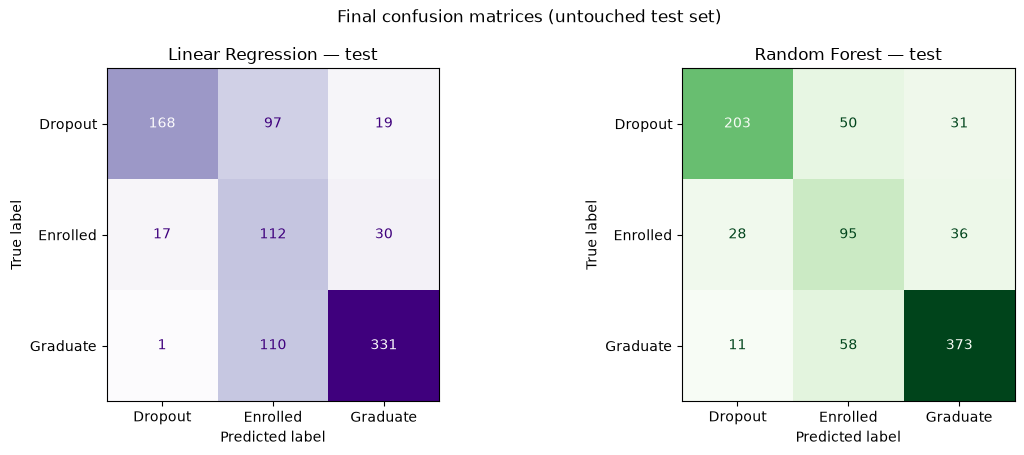

Random Forest — classification report (test set):

              precision    recall  f1-score   support

     Dropout     0.8388    0.7148    0.7719       284
    Enrolled     0.4680    0.5975    0.5249       159
    Graduate     0.8477    0.8439    0.8458       442

    accuracy                         0.7582       885
   macro avg     0.7182    0.7187    0.7142       885
weighted avg     0.7767    0.7582    0.7644       885



In [44]:

# Confusion matrices on the test set, side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay.from_predictions(y_test, lr_test_pred, labels=CLASSES,
                                        cmap="Purples", ax=axes[0], colorbar=False)
axes[0].set_title("Linear Regression — test")
ConfusionMatrixDisplay.from_predictions(y_test, rf_test_pred, labels=CLASSES,
                                        cmap="Greens", ax=axes[1], colorbar=False)
axes[1].set_title("Random Forest — test")
plt.suptitle("Final confusion matrices (untouched test set)")
plt.tight_layout(); plt.show()

print("Random Forest — classification report (test set):\n")
print(classification_report(y_test, rf_test_pred, labels=CLASSES, digits=4))

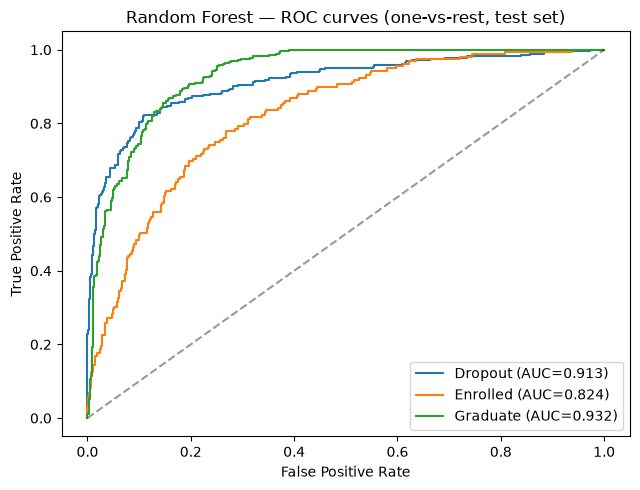

In [45]:
# Per-class ROC curves (one-vs-rest) for the Random Forest on the test set
y_test_bin = label_binarize(y_test, classes=CLASSES)
fig, ax = plt.subplots(figsize=(6.5, 5))
for i, cls in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], rf_test_proba[:, i])
    ax.plot(fpr, tpr, label=f"{cls} (AUC={auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("Random Forest — ROC curves (one-vs-rest, test set)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 6.4 Early-warning operating point — Dropout vs rest (Lab 8: threshold, ROC & PR) · *lahiru*

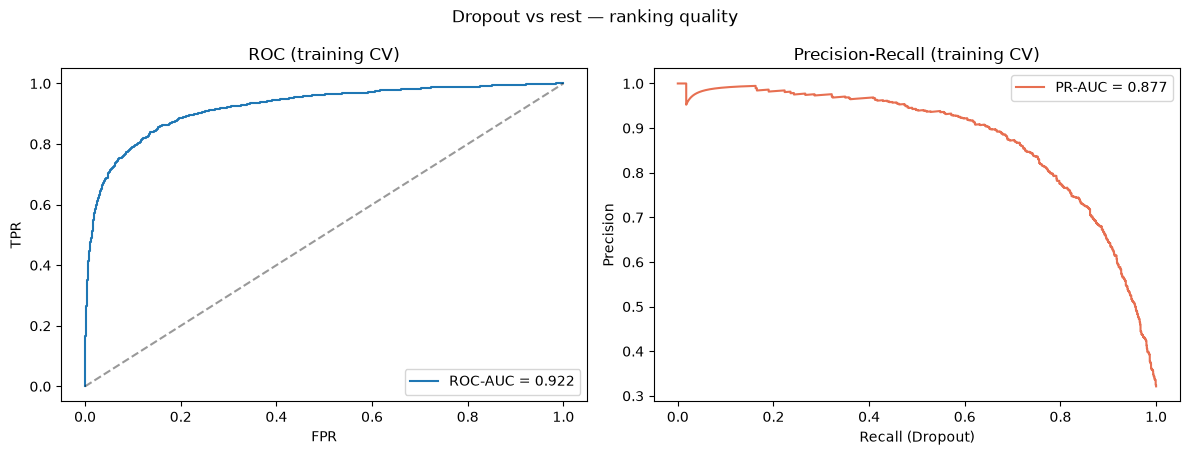

Threshold trade-off (Dropout vs rest, training CV):


,threshold,precision,recall (dropout caught),f1
0,0.3,0.6549,0.8962,0.7568
1,0.5,0.7828,0.7924,0.7876
2,0.7,0.9067,0.6412,0.7512


In [46]:
# For an early-warning system the key question is "will this student drop out?" — a binary problem
# where PR-AUC and the decision threshold matter (Lab 8). Threshold analysis is done on the TRAINING
# set via out-of-fold probabilities; the test set is used once at the end.
yb_train = (y_train == "Dropout").astype(int)
yb_test = (y_test == "Dropout").astype(int)
rf_bin = build_pipeline(best_forest(), variant="all")

oof_proba = cross_val_predict(rf_bin, X_train, yb_train, cv=cv, method="predict_proba")[:, 1]

# ROC and PR curves on the training CV probabilities
fpr, tpr, _ = roc_curve(yb_train, oof_proba); roc_auc_cv = auc(fpr, tpr)
prec, rec, _ = precision_recall_curve(yb_train, oof_proba); pr_auc_cv = auc(rec, prec)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_cv:.3f}"); axes[0].plot([0,1],[0,1],"k--",alpha=.4)
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("ROC (training CV)"); axes[0].legend(loc="lower right")
axes[1].plot(rec, prec, color="#e76f51", label=f"PR-AUC = {pr_auc_cv:.3f}")
axes[1].set_xlabel("Recall (Dropout)"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall (training CV)"); axes[1].legend()
plt.suptitle("Dropout vs rest — ranking quality"); plt.tight_layout(); plt.show()

# Threshold experiment (training CV): lower threshold catches more dropouts (higher recall)
rows = []
for t in [0.30, 0.50, 0.70]:
    pred = (oof_proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(yb_train, pred, zero_division=0),
                 "recall (dropout caught)": recall_score(yb_train, pred, zero_division=0),
                 "f1": f1_score(yb_train, pred, zero_division=0)})
print("Threshold trade-off (Dropout vs rest, training CV):")
display(pd.DataFrame(rows).round(4))

Dropout vs rest — FINAL test set
  ROC-AUC : 0.9156
  PR-AUC  : 0.8711
  Recall (dropouts caught) : 0.8063
  Precision                : 0.8092


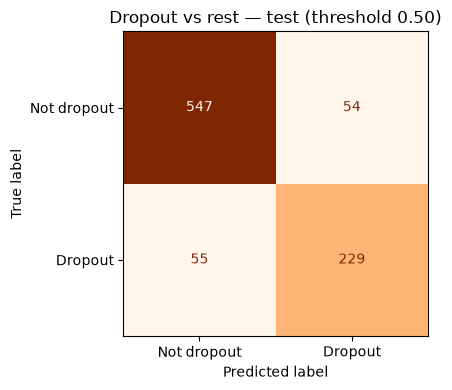

In [47]:
# Final, single evaluation on the untouched test set (threshold 0.50)
rf_bin.fit(X_train, yb_train)
test_proba = rf_bin.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= 0.50).astype(int)
print("Dropout vs rest — FINAL test set")
print(f"  ROC-AUC : {roc_auc_score(yb_test, test_proba):.4f}")
print(f"  PR-AUC  : {average_precision_score(yb_test, test_proba):.4f}")
print(f"  Recall (dropouts caught) : {recall_score(yb_test, test_pred):.4f}")
print(f"  Precision                : {precision_score(yb_test, test_pred):.4f}")
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay.from_predictions(yb_test, test_pred,
                                        display_labels=["Not dropout", "Dropout"], cmap="Oranges",
                                        ax=ax, colorbar=False)
ax.set_title("Dropout vs rest — test (threshold 0.50)"); plt.tight_layout(); plt.show()

### 6.5 Final takeaways & conclusion · *Lahiru, Kusal*

**Comparing the two algorithms (the rubric's core requirement).** On the untouched test set the **Random Forest** outperforms **Linear Regression** on every metric that matters here — accuracy, balanced accuracy, macro-F1 and MCC 
and, unlike linear regression, it produces class probabilities, giving a usable ROC-AUC. Linear Regression (applied by  rounding an ordinal success score) is a reasonable, stable baseline but is limited by its two assumptions: that the
three outcomes are **linearly separable** and **equally spaced**. The Random Forest drops both assumptions and models the non-linear interactions between semester results, fees and demographics directly.

**Evaluation lessons applied (Lab 8 / lecture notes).**
- *Accuracy alone is misleading* under the moderate class imbalance, so we led with macro-F1, balanced accuracy, MCC and per-class recall. The minority **Enrolled** class is the hardest for both models.
- *Class-imbalance handling* (class weights, SMOTE) trades a little aggregate macro-F1 for higher minority recall a deliberate choice, not a free win.

- *The decision threshold* changes the precision/recall balance: for the Dropout-vs-rest early-warning view, lowering the  threshold catches more at-risk students at the cost of more false alarms.

- *Validation vs test discipline:* every selection (hyperparameters, imbalance strategy, threshold) used stratified  cross-validation on the training set; the **test set was evaluated only once**, here.

**Limitations.** Moderate imbalance caps *Enrolled* recall; the registry codes are modelled as encoded categories; the strongest predictors are 2nd-semester results, so the model is most useful as an end-of-first-year early-warning tool;
and results reflect one institution and period (possible drift).

**Future work.** SMOTE combined with per-class threshold tuning to lift *Enrolled* recall; gradient-boosted trees (XGBoost / LightGBM / CatBoost), which usually top Random Forest on tabular data; richer feature engineering and
wrapper/embedded feature selection; and a wider randomised/Bayesian hyperparameter search with nested cross-validation for an unbiased estimate.

**Conclusion.** Using two distinct classical algorithms — an interpretable linear baseline and a non-linear ensemble in a leakage-safe pipeline, the **Random Forest is the recommended model** for predicting student dropout and academic
success, with Linear Regression retained as a transparent baseline.